# High Temperatures/Heatwaves and Mortality in France, 2000-2025: Step by Step Analysis

**Research question:** How strongly do heatwaves increase daily mortality in France, and does this effect differ between départements (e.g. by hospital capacity)?

**How this notebook is organised**

| Step | What we do |
|---|---|
| 0 | Load the packages |
| 1 | Temperature data: load → look at it → add columns → look again → univariate graphs |
| 2 | Death data (and population): load → look at it → add columns → look again → univariate graphs |
| 3 | Merge both datasets: check the keys → merge → look at the result → add columns → look again |
| 4 | Bivariate graphs: deaths vs. temperature |

**Rule for the whole notebook:** every time a dataset is loaded or changed, the next cell shows what it looks like now.

## Step 0: Packages

- `pandas`: tables (DataFrames)
- `numpy`: calculations
- `matplotlib`: static graphs (PNG/SVG for the slides)
- `plotly`: interactive graphs (map, slider)

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
import plotly.express as px
import plotly.graph_objects as go
import json
import os

plt.rcParams["figure.figsize"] = (10, 4)
os.makedirs("figures", exist_ok=True)      # folder for the saved graphs

# How the CSV files are written:
#   sep=";"            columns are separated by ";"
#   decimal=","        decimal sign is "," (French style: 25,3 °C)
#   dtype={"dep": str} the département code is text, otherwise "01" would become the number 1
#   parse_dates        the date column becomes a real date (so we can extract year, month, ...)
read = dict(sep=";", decimal=",", dtype={"dep": str}, encoding="utf-8-sig", parse_dates=["date"])

In [5]:
# ---------- Common style for ALL graphs (matplotlib and plotly) ----------
# One font, one title style, a small colour palette; every graph below uses these settings.
import plotly.io as pio

FONT = "Verdana"                 # same font as the plotly box plots
INK = "#2a3f5f"                  # dark blue-grey for titles, labels and ticks (plotly default)
BLUE = "#23449B"                 # main colour (and: men)
GREY = "#94868F"                 # second colour (and: women)
RED = "#C0392B"                  # highlight colour (heat, extreme years)
LIGHT = "#D3D3D3"                # background data (e.g. all other years)
SUMMER = "#F5E6B8"               # shading of the summer period (1 June – 15 September)

# matplotlib
plt.rcParams.update({
    "font.family": FONT, "font.size": 10,
    "axes.titlesize": 13, "axes.titlelocation": "left", "axes.titlepad": 12, "axes.titlecolor": INK,
    "axes.labelsize": 10.5, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#B0B7C3",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#EBF0F8", "grid.linewidth": 1,
    "legend.frameon": False, "legend.fontsize": 9.5,
    "figure.figsize": (10, 4.5), "figure.facecolor": "white",
    "savefig.dpi": 300, "savefig.bbox": "tight",
})

# plotly: own template based on "plotly_white", used automatically by every plotly figure
pio.templates["project"] = go.layout.Template(pio.templates["plotly_white"])
pio.templates["project"].layout.update(
    font=dict(family=FONT, size=12, color=INK),
    title=dict(font=dict(family=FONT, size=17, color=INK), x=0.02, xanchor="left"),
    colorway=[BLUE, RED, GREY, "#E69F00", "#009E73", "#56B4E9"])
pio.templates.default = "project"

# Univariate Analysis


## Step 1: Temperature Data

### 1.1 Load the file

`data/TEMPERATURE_REF_2000_2025.csv`: Météo-France, **one reference weather station per département**, one row per département and day.

In [6]:
temp = pd.read_csv("data/TEMPERATURE_REF_2000_2025.csv", **read)
print("Rows, columns:", temp.shape)
temp.head()

Rows, columns: (902215, 14)


,date,region,dep,departement,reference_station,tmin,tmax,tmean,rr,ibmn,ibmx,seuil_ibmn,seuil_ibmx,canicule_official
0,2000-01-01,Auvergne-Rhône-Alpes,01,Ain,CEYZERIAT_SAPC,1.60,5.70,3.65,0.0,NaN,NaN,20,35,NaN
1,2000-01-01,Auvergne-Rhône-Alpes,03,Allier,MONTLUCON,5.59,8.58,7.09,1.8,NaN,NaN,18,34,NaN
2,2000-01-01,Auvergne-Rhône-Alpes,07,Ardèche,ANNONAY,1.50,7.00,4.25,0.2,NaN,NaN,20,35,NaN
3,2000-01-01,Auvergne-Rhône-Alpes,15,Cantal,AURILLAC,1.00,5.90,3.45,0.0,NaN,NaN,18,32,NaN
4,2000-01-01,Auvergne-Rhône-Alpes,26,Drôme,ST-MARCEL-LES-V-INRAE,2.10,7.30,4.70,0.0,NaN,NaN,21,36,NaN


### 1.2 What is in the dataset?

**Questions to answer before making any graph:**
1. Which columns are there, and what type are they (number, text, date)?
2. Which period and how many départements?
3. Is anything missing?
4. Are the values plausible (no 60 °C, no −40 °C in summer)?

| Column | Meaning |
|---|---|
| `date` | day |
| `region`, `dep`, `departement` | region, département code, département name |
| `reference_station` | Météo-France station used for this département |
| `tmin`, `tmax`, `tmean` | minimum, maximum, mean temperature of the day (°C) |
| `rr` | precipitation (mm) |
| `ibmn`, `ibmx` | 3-day average of `tmin` / `tmax` (*indicateur biométéorologique*) |
| `seuil_ibmn`, `seuil_ibmx` | heatwave thresholds of this département |
| `canicule_official` | 1 = heatwave day by the official French definition, 0 = not |

In [7]:
# 1. Column names and types
temp.info()

<class 'pandas.DataFrame'>
RangeIndex: 902215 entries, 0 to 902214
Data columns (total 14 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   date               902215 non-null  datetime64[us]
 1   region             902215 non-null  str           
 2   dep                902215 non-null  str           
 3   departement        902215 non-null  str           
 4   reference_station  902215 non-null  str           
 5   tmin               902215 non-null  float64       
 6   tmax               902215 non-null  float64       
 7   tmean              902215 non-null  float64       
 8   rr                 902215 non-null  float64       
 9   ibmn               902025 non-null  float64       
 10  ibmx               902025 non-null  float64       
 11  seuil_ibmn         902215 non-null  int64         
 12  seuil_ibmx         902215 non-null  int64         
 13  canicule_official  902025 non-null  float64       
dtyp

In [8]:
# 2. Period and number of départements / regions
print("First day:", temp["date"].min().date(), "| last day:", temp["date"].max().date())
print("Number of days:", temp["date"].nunique())
print("Départements:", temp["dep"].nunique(), "| regions:", temp["region"].nunique())
print("Rows per département (should be the same for all):", temp.groupby("dep").size().unique())

First day: 2000-01-01 | last day: 2025-12-31
Number of days: 9497
Départements: 95 | regions: 13
Rows per département (should be the same for all): [9497]


In [9]:
# 3. Missing values per column
temp.isna().sum()
#The 190 are values for first and second January 2000 because with only two days no average could be built yet!


date                   0
region                 0
dep                    0
departement            0
reference_station      0
tmin                   0
tmax                   0
tmean                  0
rr                     0
ibmn                 190
ibmx                 190
seuil_ibmn             0
seuil_ibmx             0
canicule_official    190
dtype: int64

In [10]:
# 4. Are the values plausible? (min, max, mean of every number column)
temp.describe().round(1)

,date,tmin,tmax,tmean,rr,ibmn,ibmx,seuil_ibmn,seuil_ibmx,canicule_official
count,902215,902215.0,902215.0,902215.0,902215.0,902025.0,902025.0,902215.0,902215.0,902025.0
mean,2012-12-30 23:59:59.999999,8.0,17.5,12.7,2.1,8.0,17.5,19.5,34.1,0.0
min,2000-01-01 00:00:00,-19.7,-10.1,-12.3,0.0,-17.8,-7.6,18.0,31.0,0.0
25%,2006-07-02 00:00:00,3.5,11.6,7.8,0.0,3.7,11.6,18.0,34.0,0.0
50%,2012-12-31 00:00:00,8.2,17.4,12.7,0.0,8.1,17.4,19.0,34.0,0.0
75%,2019-07-02 00:00:00,12.7,23.3,17.8,1.6,12.5,23.3,20.0,35.0,0.0
max,2025-12-31 00:00:00,30.3,44.4,34.7,299.5,28.4,41.8,24.0,36.0,1.0
std,NaN,6.3,8.0,6.8,5.3,5.9,7.8,1.4,1.4,0.1


**What we see:**
- 95 départements (Corsica is one, code `20`) × 9,497 days = 902,215 rows.
- The heatwave columns (`ibmn`, `ibmx`, `canicule_official`) are missing only on the first 2 days, because a 3-day average needs two days before.
- Temperatures are in a realistic range.

### 1.3 Add columns

We need `year`, `month` and whether a day is in **summer**.
Summer = **1 June – 15 September**, the period of the French heat-health watch (*veille saisonnière*).

In [11]:
temp["year"] = temp["date"].dt.year
temp["month"] = temp["date"].dt.month
temp["is_summer"] = temp["date"].dt.strftime("%m-%d").between("06-01", "09-15")   # True / False

temp[["date", "dep", "tmax", "year", "month", "is_summer"]].head()

,date,dep,tmax,year,month,is_summer
0,2000-01-01,01,5.70,2000,1,False
1,2000-01-01,03,8.58,2000,1,False
2,2000-01-01,07,7.00,2000,1,False
3,2000-01-01,15,5.90,2000,1,False
4,2000-01-01,26,7.30,2000,1,False


In [12]:
# Check: how many summer days per year? (should be 107: 30 June days + 31 + 31 + 15)
temp[temp["is_summer"]].groupby("year")["date"].nunique().unique()

array([107])

### 1.4 Univariate graphs: temperature

Each graph answers one question:

| Graph | Question |
|---|---|
| Daily max. temperature vs. normal | What does a year look like, and how far above normal do hot days go? |
| Summer temperature per region (scatter / box) | Do summers get hotter, in all regions? |
| Distribution of daily max. temperature | Are there more very hot days now than 2000–2012? |
| Map | Where is it hottest, and where did it warm most? |
| Trend | How fast are French summers warming? |

### Daily max. temperature compared with normal

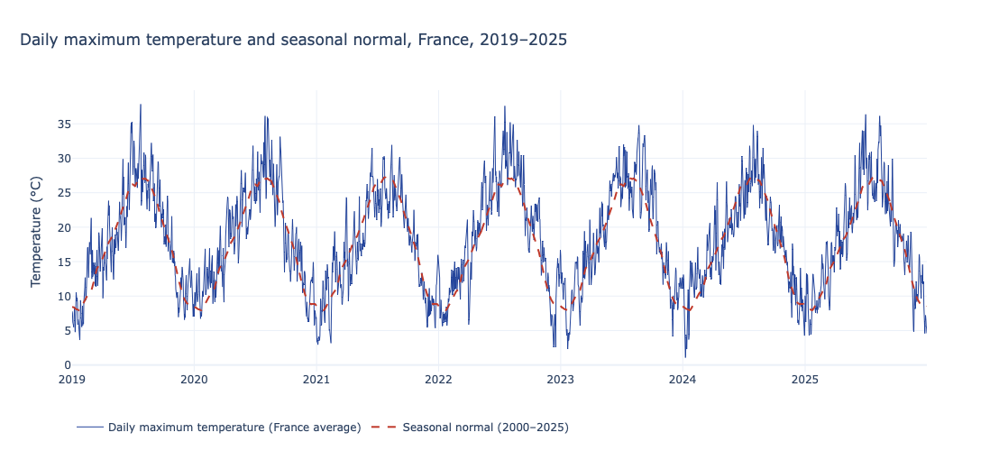

In [13]:
import plotly.graph_objects as go

START, END = "2019-01-01", "2025-12-31"   # period shown (all 26 years would be too dense to read)
VAR = "tmax"                              # "tmax" = daily max. temperature, "tmean" = daily mean

# 1. France as a whole: average of the 95 départements per day
daily = temp.groupby("date")[[VAR]].mean().rename(columns={VAR: "value"})

# 2. Seasonal normal: average value of each calendar day over 2000–2025, smoothed over 15 days
doy = daily.index.strftime("%m-%d")
normal = daily.groupby(doy)["value"].mean()
normal = pd.concat([normal.iloc[-7:], normal, normal.iloc[:7]]).rolling(15, center=True).mean().iloc[7:-7]
daily["normal"] = doy.map(normal).values

shown = daily.loc[START:END]

# 3. Plot
label = "Daily maximum temperature (France average)" if VAR == "tmax" else "Daily mean temperature (France average)"
fig_tl = go.Figure()
fig_tl.add_trace(go.Scatter(x=shown.index, y=shown["value"], mode="lines",
                            line=dict(color=BLUE, width=1), name=label))
fig_tl.add_trace(go.Scatter(x=shown.index, y=shown["normal"], mode="lines",
                            line=dict(color=RED, width=2, dash="dash"), name="Seasonal normal (2000–2025)"))
fig_tl.update_layout(title=f"{'Daily maximum' if VAR == 'tmax' else 'Daily mean'} temperature and seasonal normal, France, {START[:4]}–{END[:4]}",
                     xaxis_title="", yaxis_title="Temperature (°C)",
                     height=500,
                     legend=dict(orientation="h", y=-0.15, x=0))
fig_tl.show(config={"toImageButtonOptions": {"format": "png", "scale": 3, "filename": "temperature_timeline"}})

### Summer temperature per region, every five years
*New object:* `df_box` = one row per year and region with the average summer `tmax`.

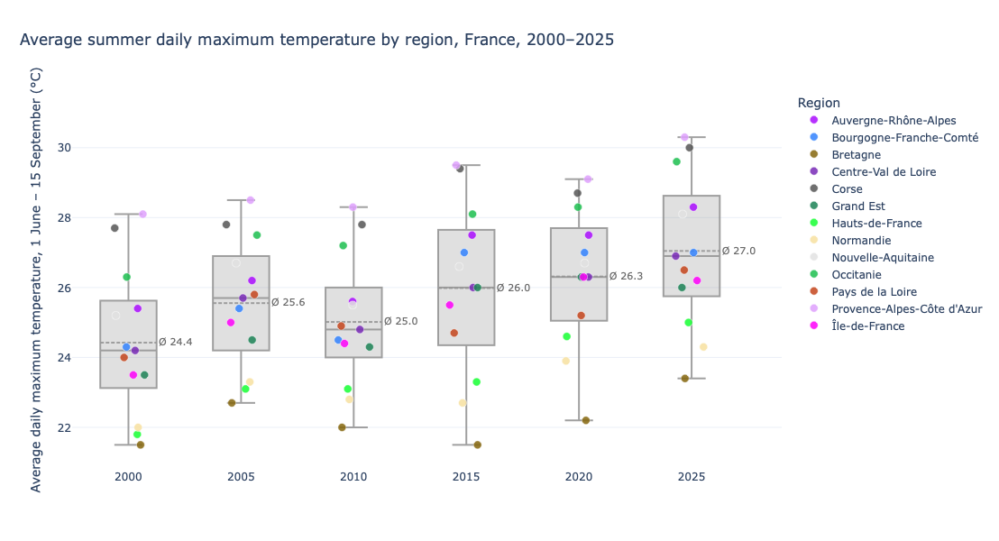

In [14]:
import plotly.graph_objects as go

years = [2000, 2005, 2010, 2015, 2020, 2025]   # one year every five years
unit = "region"                                # "region" (13 points per year) or "departement" (95 points)

# 1. One value per unit and year: average daily max. temperature in summer (1 June – 15 September)
cols = ["region"] if unit == "region" else ["region", "departement"]
df_box = (temp[temp["is_summer"] & temp["year"].isin(years)]
          .groupby(["year", *cols])["tmax"].mean().round(1).reset_index())
df_box["name"] = df_box[unit]

# x position of each year (0, 1, 2, ...) plus a small random shift so the points don't overlap
pos = {y: i for i, y in enumerate(years)}
rng = np.random.default_rng(42)                               # fixed seed: same positions every run
df_box["x"] = df_box["year"].map(pos) + rng.uniform(-0.15, 0.15, len(df_box))

# 2. Grey box plot per year
fig = go.Figure()
for y in years:
    values = df_box.loc[df_box["year"] == y, "tmax"]
    fig.add_trace(go.Box(x=[pos[y]] * len(values), y=values,
                         boxmean=True,                       # dashed line = mean
                         boxpoints=False, width=0.5,
                         fillcolor="rgba(100, 100, 100, 0.20)",
                         line_color="rgba(150, 150, 150, 0.9)",
                         hoverinfo="skip", showlegend=False))

# 3. One coloured, hoverable point per region (or département), coloured by region
colors = px.colors.qualitative.Alphabet
region_colors = {r: colors[i % len(colors)] for i, r in enumerate(sorted(df_box["region"].unique()))}
for region, d in df_box.groupby("region"):
    fig.add_trace(go.Scatter(x=d["x"], y=d["tmax"], mode="markers", name=region,
                             marker=dict(color=region_colors[region], size=9, opacity=0.85,
                                         line=dict(width=0.5, color="white")),
                             customdata=d[["name", "year"]].to_numpy(),
                             hovertemplate="<b>%{customdata[0]}</b><br>Year: %{customdata[1]}<br>"
                                           "Average summer maximum temperature: %{y:.1f} °C<extra></extra>"))

# 4. Invisible marker above each box: hover there to see the summary statistics
stats = (df_box.groupby("year")["tmax"]
         .agg(Minimum="min", Q1=lambda x: x.quantile(0.25), Median="median", Mean="mean",
              Q3=lambda x: x.quantile(0.75), Maximum="max")
         .reset_index())
stats["x"] = stats["year"].map(pos)
stats["hover_y"] = stats["Maximum"] + 0.04 * (df_box["tmax"].max() - df_box["tmax"].min())
fig.add_trace(go.Scatter(x=stats["x"], y=stats["hover_y"], mode="markers",
                         marker=dict(size=28, color="rgba(0,0,0,0)"),
                         customdata=stats[["Minimum", "Q1", "Median", "Mean", "Q3", "Maximum"]].to_numpy(),
                         text=stats["year"],
                         hovertemplate=("<b>Summer %{text}</b><br><br>"
                                        "Maximum: %{customdata[5]:.1f} °C<br>"
                                        "Q3: %{customdata[4]:.1f} °C<br>"
                                        "Mean: %{customdata[3]:.1f} °C<br>"
                                        "Median: %{customdata[2]:.1f} °C<br>"
                                        "Q1: %{customdata[1]:.1f} °C<br>"
                                        "Minimum: %{customdata[0]:.1f} °C<extra></extra>"),
                         showlegend=False))

# 4b. Mean value as text next to each box (at the height of the dashed mean line)
fig.add_trace(go.Scatter(x=stats["x"] + 0.27, y=stats["Mean"], mode="text",
                         text=[f"Ø {m:.1f}" for m in stats["Mean"]],
                         textposition="middle right",
                         textfont=dict(size=11, color="dimgray"),
                         hoverinfo="skip", showlegend=False))

# 5. Layout
fig.update_layout(
    title="Average summer daily maximum temperature by region, France, 2000–2025",
    xaxis=dict(title="", tickvals=list(pos.values()), ticktext=[str(y) for y in years],
               range=[-0.5, len(years) - 0.2]),
    yaxis=dict(title="Average daily maximum temperature, 1 June – 15 September (°C)"),
    legend_title_text="Region",
    hovermode="closest",
    height=600)
fig.show(config={"toImageButtonOptions": {"format": "png", "scale": 3, "filename": "boxplot_regions"}})

### Distribution of daily max. temperatures


*New object:* `summer_dep` = only summer days, with a new column `half` (2000–2012 vs. 2013–2025).
The map below also uses `summer_dep`.

In [15]:
summer_dep = temp[temp["is_summer"]].copy()
summer_dep["half"] = "2000–2012"
summer_dep.loc[summer_dep["year"] >= 2013, "half"] = "2013–2025"

# look at the new object: only summer days, one new column
print(summer_dep.shape)
summer_dep["half"].value_counts()

(264290, 18)


half
2000–2012    132145
2013–2025    132145
Name: count, dtype: int64

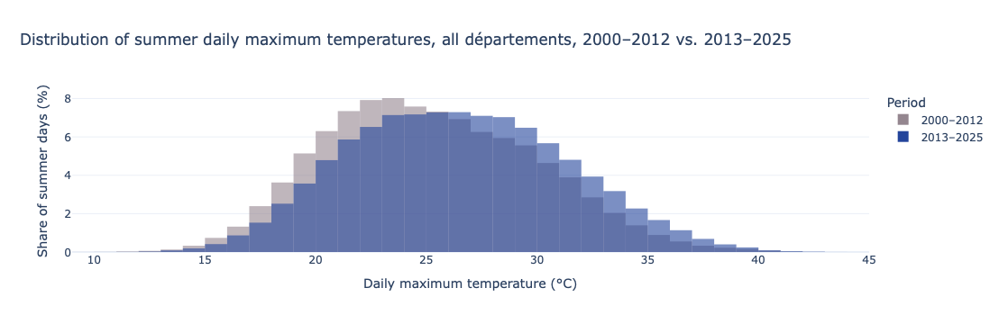

In [16]:
fig_hist = px.histogram(summer_dep,
                        x="tmax",
                        color="half",                     # one colour per period
                        barmode="overlay",                # both on top of each other
                        histnorm="percent",               # % of days, so both periods are comparable
                        nbins=60,
                        opacity=0.6,
                        labels={"tmax": "Daily maximum temperature (°C)", "half": "Period"},
                        color_discrete_sequence=[GREY, BLUE],
                        title="Distribution of summer daily maximum temperatures, all départements, 2000–2012 vs. 2013–2025")
fig_hist.update_layout(yaxis_title="Share of summer days (%)")

fig_hist.show(config={"toImageButtonOptions": {"format": "png", "scale": 3, "filename": "distribution_daily_max_temp"}})

### Map: Summer Max Temp.per region

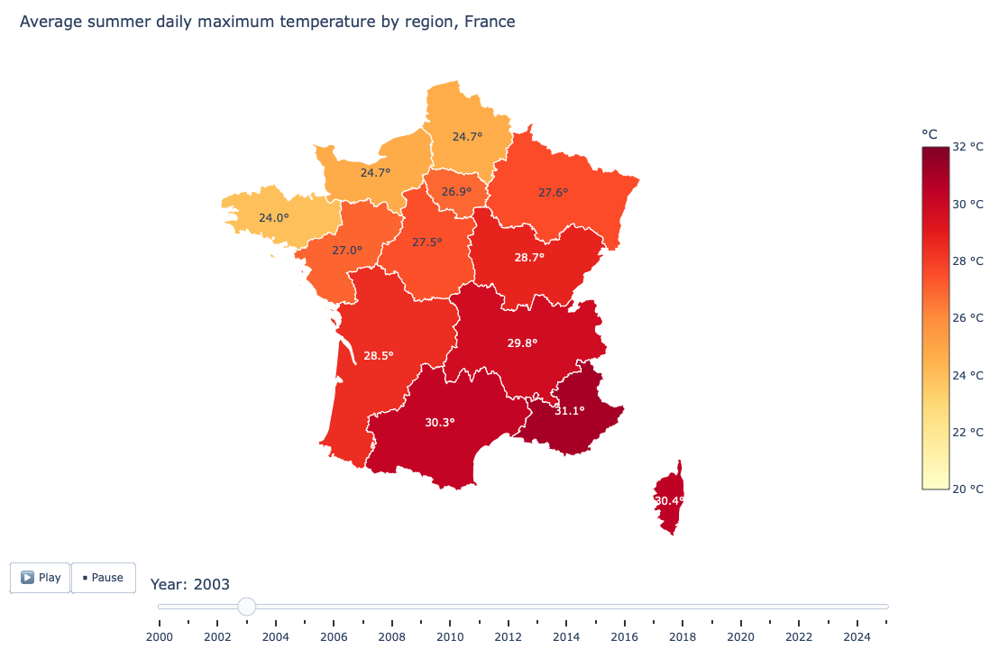

In [17]:
from pathlib import Path
from plotly.colors import sample_colorscale
import plotly.graph_objects as go
import urllib.request
import os

VAR = "tmax"      # "tmax" = average daily max. temperature (like the other plots), "tmean" = daily mean

# --- 1. Summer value per region and year (summer_dep = summer days per département, from the histogram cell) ---
reg_year = (summer_dep.groupby(["year", "region"], as_index=False)[VAR].mean()
                      .rename(columns={VAR: "summer_temp"}))
reg_year["summer_temp"] = reg_year["summer_temp"].round(2)
# anomaly = difference to the region's own 2000–2025 average (shown when hovering)
reg_year["anomaly"] = (reg_year["summer_temp"]
                       - reg_year.groupby("region")["summer_temp"].transform("mean")).round(2)

# --- 2. Simplified region outlines (downloaded once, saved next to the notebook) ---
GEO = Path("regions_france.geojson")
if not GEO.exists():
    url = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/regions-version-simplifiee.geojson"
    urllib.request.urlretrieve(url, GEO)
regions_simple = json.loads(GEO.read_text(encoding="utf-8"))

# --- 3. Turn each region outline into x/y coordinates for plotting ---
COS_LAT = np.cos(np.radians(46.5))          # simple projection: keeps France's proportions
def outline(geom):
    polys = [geom["coordinates"]] if geom["type"] == "Polygon" else geom["coordinates"]
    xs, ys = [], []
    for poly in polys:
        ring = poly[0]                       # outer ring
        xs += [lon * COS_LAT for lon, lat in ring] + [None]
        ys += [lat for lon, lat in ring] + [None]
    return xs, ys

shapes = {f["properties"]["nom"]: outline(f["geometry"]) for f in regions_simple["features"]}
names = sorted(shapes)
assert set(names) == set(reg_year["region"]), "region names in data and map do not match"

def label_position(xs, ys):                  # average of the outline points
    pts = [(x, y) for x, y in zip(xs, ys) if x is not None]
    return np.mean([p[0] for p in pts]), np.mean([p[1] for p in pts])
centres = {n: label_position(*shapes[n]) for n in names}
centres["Corse"] = (9.1 * COS_LAT, 42.1)

# --- 4. Colours: same scale for every year ---
CMIN = float(np.floor(reg_year["summer_temp"].min()))
CMAX = float(np.ceil(reg_year["summer_temp"].max()))
SCALE = "YlOrRd"
SURFACE = "white"                             # background colour (INK comes from the style cell)
colour = lambda v: sample_colorscale(SCALE, [(v - CMIN) / (CMAX - CMIN)])[0]
map_years = sorted(reg_year["year"].unique())
val = reg_year.set_index(["year", "region"])

# --- 5. All shapes and labels for one year ---
def traces_for(year):
    out = []
    for n in names:
        v, a = val.loc[(year, n), "summer_temp"], val.loc[(year, n), "anomaly"]
        xs, ys = shapes[n]
        out.append(go.Scatter(x=xs, y=ys, fill="toself", fillcolor=colour(v), mode="lines",
                              line=dict(color="white", width=1.2), hoveron="fills",
                              text=f"<b>{n}</b><br>{year}: {v:.1f} °C<br>vs 2000–25 average: {a:+.1f} °C",
                              hoverinfo="text", showlegend=False))
    out.append(go.Scatter(x=[centres[n][0] for n in names], y=[centres[n][1] for n in names],
                          mode="text", text=[f"{val.loc[(year, n), 'summer_temp']:.1f}°" for n in names],
                          textfont=dict(size=12, color=["white" if (val.loc[(year, n), "summer_temp"] - CMIN) / (CMAX - CMIN) > 0.65
                                                      else INK for n in names]),
                          hoverinfo="skip", showlegend=False))
    return out

# --- 6. Figure with year slider and play button ---
START = 2003                                  # the map opens on the 2003 heatwave
colourbar = go.Scatter(x=[None], y=[None], mode="markers", hoverinfo="skip", showlegend=False,
                       marker=dict(colorscale=SCALE, cmin=CMIN, cmax=CMAX, color=[CMIN], showscale=True,
                                   colorbar=dict(title="°C", ticksuffix=" °C", len=0.75)))
fig_map2 = go.Figure(data=traces_for(START) + [colourbar],
                     frames=[go.Frame(name=str(y), data=traces_for(y), traces=list(range(len(names) + 1)))
                             for y in map_years])
title = "Average summer daily maximum temperature" if VAR == "tmax" else "Summer mean temperature"
fig_map2.update_layout(
    title=dict(text=f"{title} by region, France"),
    xaxis=dict(visible=False), yaxis=dict(visible=False, scaleanchor="x"),
    height=720, margin=dict(l=10, r=10, t=60, b=10),
    paper_bgcolor=SURFACE, plot_bgcolor=SURFACE, 
    sliders=[dict(active=map_years.index(START), currentvalue=dict(prefix="Year: ", font=dict(size=16)),
                  pad=dict(t=10), len=0.84, x=0.16,
                  steps=[dict(label=str(y), method="animate",
                              args=[[str(y)], dict(mode="immediate", frame=dict(duration=0, redraw=True),
                                                   transition=dict(duration=0))]) for y in map_years])],
    updatemenus=[dict(type="buttons", direction="left", x=0.0, y=0.02, xanchor="left", yanchor="top",
                      pad=dict(t=12), showactive=False,
                      buttons=[dict(label="▶️ Play", method="animate",
                                    args=[None, dict(frame=dict(duration=700, redraw=True), fromcurrent=True,
                                                     transition=dict(duration=0))]),
                               dict(label="■ Pause", method="animate",
                                    args=[[None], dict(mode="immediate", frame=dict(duration=0, redraw=False))])])],
)
fig_map2.show(config={"toImageButtonOptions": {"format": "png", "scale": 3, "filename": "map_summer_temperature"}})

# save as interactive HTML in the folder "figures" (not uploaded to GitHub)
os.makedirs("figures", exist_ok=True)
fig_map2.write_html("figures/map_summer_temperature.html", include_plotlyjs=True, auto_play=False)

### Trend of summer temperature
*New object:* `france` = one row per day, average over all 95 départements.

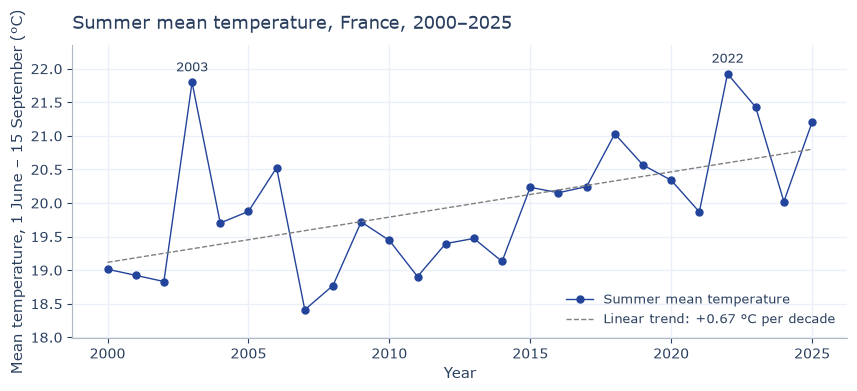

In [18]:
import os

VAR = "tmean"   # "tmean" = daily mean temperature, "tmax" = daily max. temperature

# whole of France: average over the 95 départements for each day
france = temp.groupby("date")[["tmin", "tmax", "tmean"]].mean().reset_index()
france["year"] = france["date"].dt.year
france["is_summer"] = france["date"].dt.strftime("%m-%d").between("06-01", "09-15")

# average summer temperature (1 June – 15 September) per year, France as a whole
st = france[france["is_summer"]].groupby("year")[VAR].mean()

# linear trend: straight line fitted through the yearly values
slope, icpt = np.polyfit(st.index, st.values, 1)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(st.index, st.values, color=BLUE, marker="o", ms=5, lw=1,
        label="Summer mean temperature" if VAR == "tmean" else "Summer mean of daily max. temperature")
ax.plot(st.index, icpt + slope * st.index, color="gray", lw=1, ls="--",
        label=f"Linear trend: {slope * 10:+.2f} °C per decade")
for yr in [2003, 2022]:                                   # label the two hottest summers
    ax.annotate(str(yr), (yr, st[yr]), xytext=(0, 8), textcoords="offset points",
                ha="center", fontsize=9.5)
ax.set_title("Summer mean temperature, France, 2000–2025" if VAR == "tmean" else "Summer mean of the daily maximum temperature, France, 2000–2025")
ax.set_xlabel("Year")
ax.set_ylabel("Mean temperature, 1 June – 15 September (°C)")
ax.margins(y=0.12)                                        # some space above the highest point for the labels
ax.legend(loc="lower right")                              # legend where it doesn't cover any points

# save the figure as PNG for the slides (before plt.show(), so the saved image is complete)
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/summer_temperature_trend.png", dpi=300, bbox_inches="tight")
plt.show()
fig.savefig("figures/summer_temperature_trend.svg", bbox_inches="tight")

## Step 2: Death Data

### 2.1 Load the file

`data/DECES_2000_2025.csv`: INSEE, *Fichier des personnes décédées*, counted per département and day, split into sex × age group.

In [20]:
deaths = pd.read_csv("data/DECES_2000_2025.csv", **read)
print("Rows, columns:", deaths.shape)
deaths.head()

Rows, columns: (902215, 13)


,date,region,dep,departement,deces_total,deces_F_0-64,deces_F_65-74,deces_F_75-84,deces_F_85+,deces_M_0-64,deces_M_65-74,deces_M_75-84,deces_M_85+
0,2000-01-01,Auvergne-Rhône-Alpes,01,Ain,14,0,0,2,6,1,2,1,2
1,2000-01-01,Auvergne-Rhône-Alpes,03,Allier,20,3,0,5,4,5,1,1,1
2,2000-01-01,Auvergne-Rhône-Alpes,07,Ardèche,9,1,0,1,3,1,0,2,1
3,2000-01-01,Auvergne-Rhône-Alpes,15,Cantal,15,2,1,2,3,2,1,3,1
4,2000-01-01,Auvergne-Rhône-Alpes,26,Drôme,12,2,2,0,4,1,0,0,3


### 2.2 What is in the dataset?

| Column | Meaning |
|---|---|
| `date`, `region`, `dep`, `departement` | as in the temperature file |
| `deces_total` | all deaths on that day in that département |
| `deces_F_0-64` … `deces_F_85+` | deaths of women in 4 age groups |
| `deces_M_0-64` … `deces_M_85+` | deaths of men in 4 age groups |

Same questions as for temperature: columns, period, missing values, plausible values.
And one extra: **do the 8 groups add up to the total?**

In [21]:
deaths.info()

<class 'pandas.DataFrame'>
RangeIndex: 902215 entries, 0 to 902214
Data columns (total 13 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   date           902215 non-null  datetime64[us]
 1   region         902215 non-null  str           
 2   dep            902215 non-null  str           
 3   departement    902215 non-null  str           
 4   deces_total    902215 non-null  int64         
 5   deces_F_0-64   902215 non-null  int64         
 6   deces_F_65-74  902215 non-null  int64         
 7   deces_F_75-84  902215 non-null  int64         
 8   deces_F_85+    902215 non-null  int64         
 9   deces_M_0-64   902215 non-null  int64         
 10  deces_M_65-74  902215 non-null  int64         
 11  deces_M_75-84  902215 non-null  int64         
 12  deces_M_85+    902215 non-null  int64         
dtypes: datetime64[us](1), int64(9), str(3)
memory usage: 112.7 MB


In [22]:
print("First day:", deaths["date"].min().date(), "| last day:", deaths["date"].max().date())
print("Départements:", deaths["dep"].nunique())
print("Missing values in total:", deaths.isna().sum().sum())
print("All deaths 2000–2025:", f'{deaths["deces_total"].sum():,}')

First day: 2000-01-01 | last day: 2025-12-31
Départements: 95
Missing values in total: 0
All deaths 2000–2025: 14,837,972


In [23]:
deaths.describe().round(1)

,date,deces_total,deces_F_0-64,deces_F_65-74,deces_F_75-84,deces_F_85+,deces_M_0-64,deces_M_65-74,deces_M_75-84,deces_M_85+
count,902215,902215.0,902215.0,902215.0,902215.0,902215.0,902215.0,902215.0,902215.0,902215.0
mean,2012-12-30 23:59:59.999999,16.4,1.0,0.9,2.0,4.3,2.0,1.6,2.3,2.4
min,2000-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,2006-07-02 00:00:00,8.0,0.0,0.0,1.0,2.0,0.0,0.0,1.0,1.0
50%,2012-12-31 00:00:00,14.0,1.0,1.0,1.0,4.0,1.0,1.0,2.0,2.0
75%,2019-07-02 00:00:00,22.0,1.0,1.0,3.0,6.0,3.0,2.0,3.0,3.0
max,2025-12-31 00:00:00,325.0,59.0,23.0,68.0,114.0,80.0,25.0,25.0,36.0
std,NaN,11.9,1.3,1.2,2.0,3.6,2.2,1.7,2.2,2.2


In [24]:
# the 8 sex × age columns
age_sex = [c for c in deaths.columns if c.startswith("deces_") and c != "deces_total"]
print(age_sex)

# do they add up to deces_total? (difference = deaths with unknown age)
diff = deaths["deces_total"] - deaths[age_sex].sum(axis=1)
print("Days where the groups do not add up:", (diff != 0).sum(), "| deaths with unknown age/sex:", diff.sum())

['deces_F_0-64', 'deces_F_65-74', 'deces_F_75-84', 'deces_F_85+', 'deces_M_0-64', 'deces_M_65-74', 'deces_M_75-84', 'deces_M_85+']
Days where the groups do not add up: 0 | deaths with unknown age/sex: 0


### 2.3 Add columns

In [25]:
deaths["year"] = deaths["date"].dt.year
deaths["is_summer"] = deaths["date"].dt.strftime("%m-%d").between("06-01", "09-15")

deaths[["date", "dep", "deces_total", "year", "is_summer"]].head()

,date,dep,deces_total,year,is_summer
0,2000-01-01,01,14,2000,False
1,2000-01-01,03,20,2000,False
2,2000-01-01,07,9,2000,False
3,2000-01-01,15,15,2000,False
4,2000-01-01,26,12,2000,False


### 2.4 Population data

To compare years we need **death rates** (deaths per 100,000 inhabitants), not only counts, because the population grows and ages.

`data/POPULATION_DEP_2000_2025.csv`: INSEE population estimates on **1 January**, per département and year, by sex and age group.

In [26]:
pop = pd.read_csv("data/POPULATION_DEP_2000_2025.csv", sep=";", dtype={"dep": str})
print(pop.shape)
pop.head()

(2470, 13)


,year,dep,population,population_M,population_F,population_M_0-64,population_F_0-64,population_M_65-74,population_F_65-74,population_M_75-84,population_F_75-84,population_M_85+,population_F_85+
0,2000,01,521103,258345,262758,227695,220581,18712,21349,9099,13443,2839,7385
1,2000,02,536260,262240,274020,227717,222990,21492,27316,10309,16299,2722,7415
2,2000,03,344710,165534,179176,134109,132842,18066,22984,10058,15172,3301,8178
3,2000,04,141454,69174,72280,57060,56332,7187,8083,3747,5166,1180,2699
4,2000,05,122542,60149,62393,50495,49659,5638,6284,3050,4337,966,2113


In [27]:
print("Years:", pop["year"].min(), "–", pop["year"].max(), "| départements:", pop["dep"].nunique())
print("Same départements as in the death file:", set(pop["dep"]) == set(deaths["dep"]))

# population of mainland France per year (should rise from ~59 to ~66 million)
(pop.groupby("year")["population"].sum() / 1e6).round(1)

Years: 2000 – 2025 | départements: 95
Same départements as in the death file: True


year
2000    58.9
2001    59.3
2002    59.7
2003    60.1
2004    60.5
2005    61.0
2006    61.4
2007    61.8
2008    62.1
2009    62.5
2010    62.8
2011    63.1
2012    63.4
2013    63.7
2014    64.0
2015    64.3
2016    64.5
2017    64.6
2018    64.8
2019    65.1
2020    65.3
2021    65.5
2022    65.8
2023    66.2
2024    66.4
2025    66.6
Name: population, dtype: float64

### 2.5 Univariate graphs: deaths

| Graph | Question |
|---|---|
| Deaths per day | How many people die per day, and what are the peaks? |
| Seasonal profile | When in the year do people die? (winter peak, summer peaks) |
| Summer death rate | Is summer mortality rising when we take population into account? |
| Summer death rate by sex | Do women and men differ? |
| Deaths by age group and sex | Who dies? |

### Deaths per day (version 1)

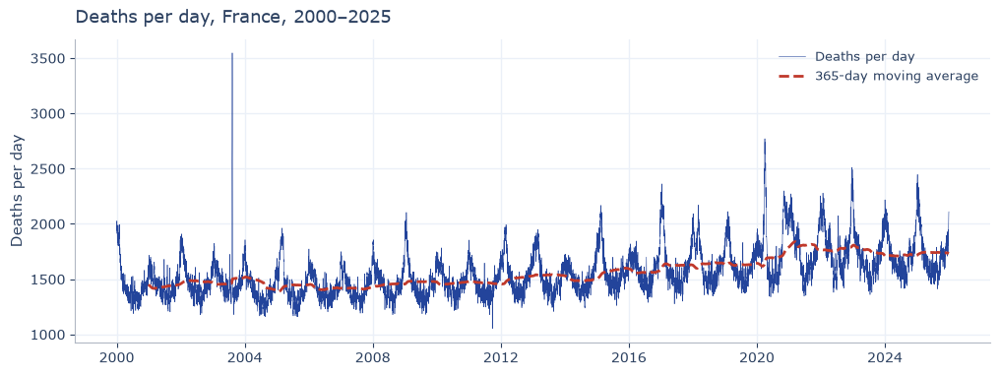

count    9497.0
mean     1562.0
std       213.0
min      1053.0
25%      1412.0
50%      1521.0
75%      1667.0
max      3547.0

The 5 days with the most deaths:
date
2003-08-12    3547
2003-08-13    3302
2003-08-11    3211
2020-04-01    2771
2003-08-10    2749


In [29]:
france_deaths = deaths.groupby("date")["deces_total"].sum()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(france_deaths, color=BLUE, linewidth=0.4, label="Deaths per day")
ax.plot(france_deaths.rolling(365).mean(), color=RED, lw=2, ls="--", label="365-day moving average")
ax.set_title("Deaths per day, France, 2000–2025")
ax.set_ylabel("Deaths per day")
ax.legend()
fig.savefig("figures/deaths_per_dayv1.svg", bbox_inches="tight")
plt.show()

print(france_deaths.describe().round(0).to_string())
print()
print("The 5 days with the most deaths:")
print(france_deaths.nlargest(5).to_string())

### Deaths per day (version 2)

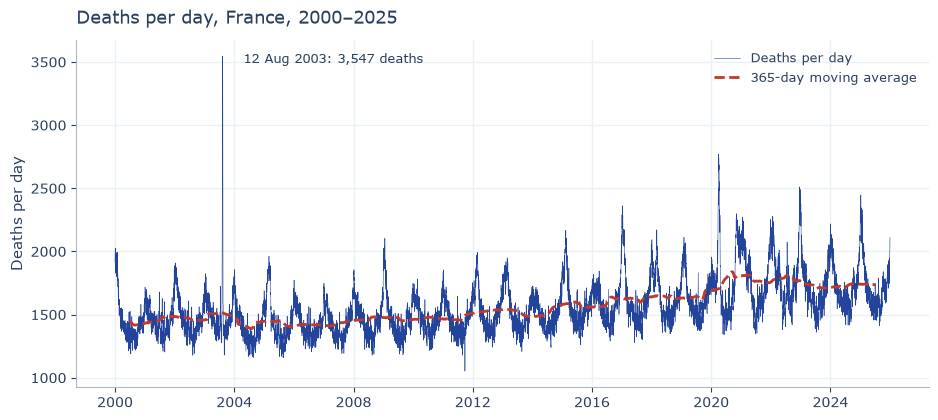

Days with the most deaths:
date
2003-08-12    3547
2003-08-13    3302
2003-08-11    3211
2020-04-01    2771
2003-08-10    2749


In [25]:
import os

# deaths per day in France (sum over all départements)
daily_deaths = deaths.groupby("date")["deces_total"].sum()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(daily_deaths.index, daily_deaths, color=BLUE, lw=0.4, label="Deaths per day")
ax.plot(daily_deaths.index, daily_deaths.rolling(365, center=True).mean(), color=RED, lw=2, ls="--",
        label="365-day moving average")
peak = daily_deaths.idxmax()                                   # the day with the most deaths
ax.annotate(f"{peak:%d %b %Y}: {daily_deaths[peak]:,} deaths", (peak, daily_deaths[peak]),
            xytext=(15, -5), textcoords="offset points", fontsize=9.5)
ax.set_title("Deaths per day, France, 2000–2025")
ax.set_ylabel("Deaths per day")
ax.legend(loc="upper right")
ax.spines[["top", "right"]].set_visible(False)

os.makedirs("figures", exist_ok=True)
fig.savefig("figures/deaths_per_day.png", dpi=300, bbox_inches="tight")
fig.savefig("figures/deaths_per_day.svg", bbox_inches="tight")
plt.show()

print("Days with the most deaths:")
print(daily_deaths.nlargest(5).to_string())

### Boxplot Deaths

In [26]:
import plotly.graph_objects as go

years = [2000, 2005, 2010, 2015, 2020, 2025]   # same years as the temperature box plot
RATE = "standardised"                          # "standardised" (age-standardised) or "crude" (all deaths / all inhabitants)

# 1. Deaths (whole year) and population per region, year and sex × age group
groups = [f"{s}_{a}" for s in ["F", "M"] for a in ["0-64", "65-74", "75-84", "85+"]]
pop = pd.read_csv("data/POPULATION_DEP_2000_2025.csv", sep=";", dtype={"dep": str})
pop["region"] = pop["dep"].map(deaths.drop_duplicates("dep").set_index("dep")["region"])

d_reg = deaths.groupby(["region", "year"])[[f"deces_{g}" for g in groups] + ["deces_total"]].sum()
p_reg = pop.groupby(["region", "year"])[[f"population_{g}" for g in groups] + ["population"]].sum()

# 2. Crude rate: all deaths / all inhabitants
crude = d_reg["deces_total"] / p_reg["population"] * 1e5

# 3. Age-standardised rate: death rate of each sex × age group, weighted with ONE fixed age structure
#    (France 2000–2025), so regions and years are compared as if they had the same age structure
group_rates = pd.DataFrame({g: d_reg[f"deces_{g}"] / p_reg[f"population_{g}"] for g in groups})
weights = pop[[f"population_{g}" for g in groups]].sum()
weights = (weights / weights.sum()).values
standardised = (group_rates * weights).sum(axis=1) * 1e5

df_box = pd.DataFrame({"crude": crude, "standardised": standardised}).reset_index()
df_box = df_box[df_box["year"].isin(years)]
df_box["value"] = df_box[RATE].round(0)
df_box["name"] = df_box["region"]

# x position of each year (0, 1, 2, ...) plus a small random shift so the points don't overlap
pos = {y: i for i, y in enumerate(years)}
rng = np.random.default_rng(42)
df_box["x"] = df_box["year"].map(pos) + rng.uniform(-0.15, 0.15, len(df_box))

# 4. Grey box plot per year
fig = go.Figure()
for y in years:
    values = df_box.loc[df_box["year"] == y, "value"]
    fig.add_trace(go.Box(x=[pos[y]] * len(values), y=values, boxmean=True, boxpoints=False, width=0.5,
                         fillcolor="rgba(100, 100, 100, 0.20)", line_color="rgba(150, 150, 150, 0.9)",
                         hoverinfo="skip", showlegend=False))

# 5. One coloured, hoverable point per region (same colours as the temperature box plot)
colors = px.colors.qualitative.Alphabet
region_colors = {r: colors[i % len(colors)] for i, r in enumerate(sorted(df_box["region"].unique()))}
for region, d in df_box.groupby("region"):
    fig.add_trace(go.Scatter(x=d["x"], y=d["value"], mode="markers", name=region,
                             marker=dict(color=region_colors[region], size=9, opacity=0.85,
                                         line=dict(width=0.5, color="white")),
                             customdata=d[["name", "year", "crude", "standardised"]].to_numpy(),
                             hovertemplate="<b>%{customdata[0]}</b><br>Year: %{customdata[1]}<br>"
                                           "Crude rate: %{customdata[2]:.0f} per 100,000<br>"
                                           "Age-standardised: %{customdata[3]:.0f} per 100,000<extra></extra>"))

# 6. Mean value as text next to each box
stats = df_box.groupby("year")["value"].mean().reset_index(name="Mean")
stats["x"] = stats["year"].map(pos)
fig.add_trace(go.Scatter(x=stats["x"] + 0.27, y=stats["Mean"], mode="text",
                         text=[f"Ø {m:.0f}" for m in stats["Mean"]], textposition="middle right",
                         textfont=dict(size=11, color="dimgray"), hoverinfo="skip", showlegend=False))

# 7. Layout
label = "Age-standardised death rate" if RATE == "standardised" else "Death rate"
fig.update_layout(
    title=f"{label} by region, France, 2000–2025",
    xaxis=dict(title="", tickvals=list(pos.values()), ticktext=[str(y) for y in years],
               range=[-0.5, len(years) - 0.2]),
    yaxis=dict(title="Deaths per 100,000 inhabitants per year"),
    legend_title_text="Region", hovermode="closest", height=600)
fig.write_html("figures/boxplot_death_rate_regions.html")
fig.show(config={"toImageButtonOptions": {"format": "png", "scale": 3, "filename": "boxplot_death_rate_regions"}})

### Seasonal Profile: every year on the same calendar axis

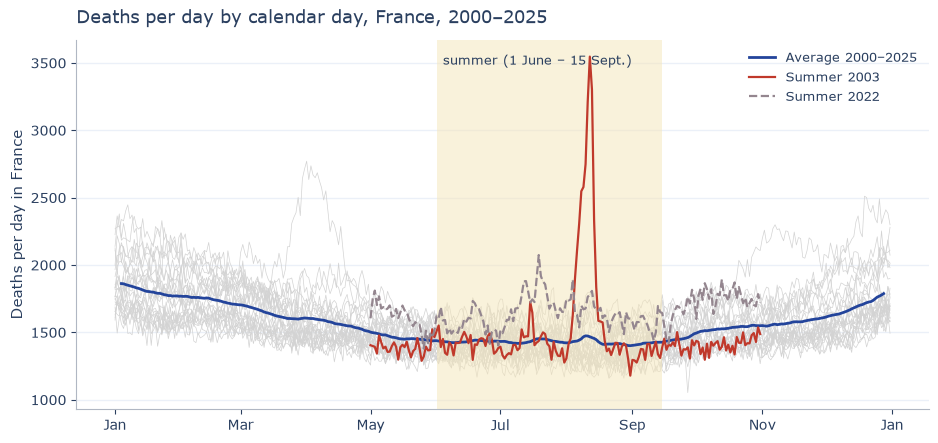

In [27]:
import os

# deaths per day in France, and the average for each calendar day over 2000–2025
france_deaths = deaths.groupby("date")["deces_total"].sum().to_frame("deaths")
france_deaths["year"] = france_deaths.index.year
france_deaths["doy"] = pd.to_datetime("2001-" + france_deaths.index.strftime("%m-%d"), errors="coerce")  # same axis for all years
france_deaths = france_deaths.dropna(subset=["doy"])                       # drops 29 February
typical = france_deaths.groupby("doy")["deaths"].mean()

fig, ax = plt.subplots(figsize=(11, 4.8))
for yr in sorted(france_deaths["year"].unique()):                         # all years in light grey
    d = france_deaths[france_deaths["year"] == yr]
    ax.plot(d["doy"], d["deaths"], color=LIGHT, lw=0.5, zorder=1)
ax.plot(typical.index, typical.rolling(7, center=True).mean(), color=BLUE, lw=2, label="Average 2000–2025", zorder=2)
for yr, col, ls in [(2003, RED, "-"), (2022, GREY, "--")]:
    d = france_deaths[(france_deaths["year"] == yr) & (france_deaths["doy"].dt.month.isin(range(5, 11)))]
    ax.plot(d["doy"], d["deaths"], color=col, lw=1.6, ls=ls, label=f"Summer {yr}", zorder=3)
ax.axvspan(pd.Timestamp("2001-06-01"), pd.Timestamp("2001-09-15"), color=SUMMER, alpha=0.5, lw=0)
ax.text(pd.Timestamp("2001-06-04"), ax.get_ylim()[1] * 0.97, "summer (1 June – 15 Sept.)", fontsize=9, va="top")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_ylabel("Deaths per day in France")
ax.set_title("Deaths per day by calendar day, France, 2000–2025")
ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
ax.spines[["top", "right"]].set_visible(False)

os.makedirs("figures", exist_ok=True)
fig.savefig("figures/deaths_seasonal_profile.png", dpi=300, bbox_inches="tight")
plt.show()

### Seasonal profile, relative to the average day of each year

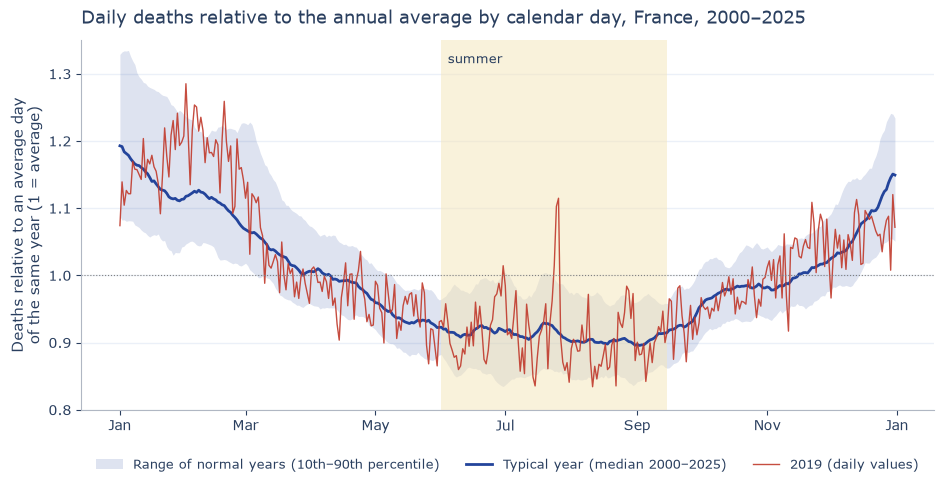

In [28]:
import os

HIGHLIGHT = 2019        # one recent year with typical heatwaves (late June and late July 2019); None = no highlight

# 1. Deaths per day in France, relative to the average day of the same year
#    (1.0 = an average day of that year; this removes the long-term rise due to population ageing)
fd = deaths.groupby("date")["deces_total"].sum().to_frame("deaths")
fd["year"] = fd.index.year
fd["relative"] = fd["deaths"] / fd.groupby("year")["deaths"].transform("mean")
fd["doy"] = pd.to_datetime("2001-" + fd.index.strftime("%m-%d"), errors="coerce")   # same calendar axis for all years
fd = fd.dropna(subset=["doy"])                                                    # drops 29 February

# 2. Typical pattern: median of each calendar day over 2000–2025, and the range of normal years (10th–90th percentile)
by_day = fd.groupby("doy")["relative"]
median = by_day.median().rolling(7, center=True, min_periods=1).mean()
low = by_day.quantile(0.10).rolling(7, center=True, min_periods=1).mean()
high = by_day.quantile(0.90).rolling(7, center=True, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.fill_between(median.index, low, high, color=BLUE, alpha=0.15, lw=0, label="Range of normal years (10th–90th percentile)")
ax.plot(median.index, median, color=BLUE, lw=2, label="Typical year (median 2000–2025)")
if HIGHLIGHT:
    d = fd[fd["year"] == HIGHLIGHT]
    ax.plot(d["doy"], d["relative"], color=RED, lw=1, alpha=0.9, label=f"{HIGHLIGHT} (daily values)")
ax.axhline(1, color="gray", lw=0.8, ls=":")
ax.axvspan(pd.Timestamp("2001-06-01"), pd.Timestamp("2001-09-15"), color=SUMMER, alpha=0.5, lw=0)
ax.text(pd.Timestamp("2001-06-04"), 1.33, "summer", fontsize=9, va="top")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_ylim(0.8, 1.35)
ax.set_ylabel("Deaths relative to an average day\nof the same year (1 = average)")
ax.set_title("Daily deaths relative to the annual average by calendar day, France, 2000–2025")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
ax.grid(axis="x", visible=False)
ax.spines[["top", "right"]].set_visible(False)

os.makedirs("figures", exist_ok=True)
fig.savefig("figures/deaths_seasonal_profile.png", dpi=300, bbox_inches="tight")
plt.show()

### Summer death rate per 100,000 inhabitants

*New objects:* `pop_year` (population per year), `deaths_year` (summer deaths per year), `rate`.

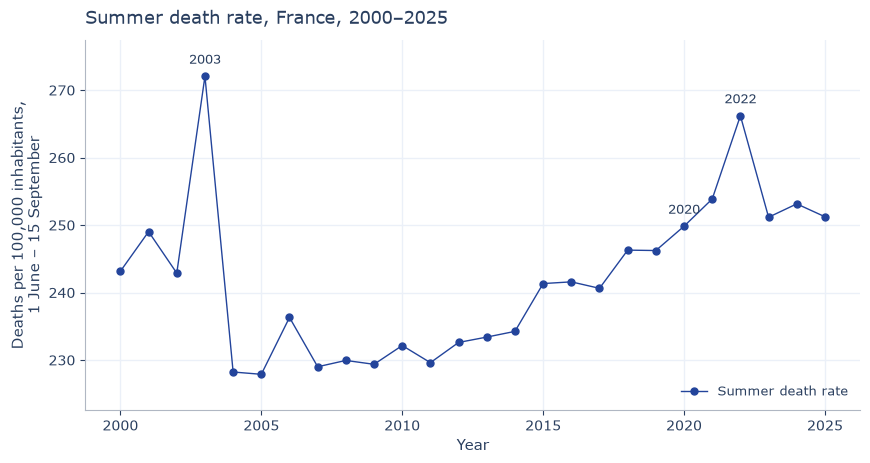

,summer_deaths,population,rate_per_100k
year,,,
2000,143119,58858198,243.2
2001,147588,59266572,249.0
2002,144968,59685899,242.9
2003,163512,60101841,272.1
2004,138090,60505421,228.2
2005,138928,60963264,227.9
2006,145096,61399733,236.3
2007,141515,61795238,229.0
2008,142875,62134866,229.9


In [42]:
import os

# 1. Population on 1 January per département and year (INSEE estimates, Corsica 2A + 2B = 20)
pop = pd.read_csv("data/POPULATION_DEP_2000_2025.csv", sep=";", dtype={"dep": str})
pop_year = pop.groupby("year")["population"].sum()                         # population of mainland France

# 2. Summer deaths (1 June – 15 September) per year
deaths["is_summer"] = deaths["date"].dt.strftime("%m-%d").between("06-01", "09-15")
deaths_year = deaths[deaths["is_summer"]].groupby("year")["deces_total"].sum()

# 3. Summer death rate per 100,000 inhabitants
rate = (deaths_year / pop_year * 1e5).rename("rate_per_100k")
table_rate = pd.DataFrame({"summer_deaths": deaths_year, "population": pop_year, "rate_per_100k": rate.round(1)})

# 4. Plot
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(rate.index, rate.values, color=BLUE, marker="o", ms=5, lw=1, label="Summer death rate")
for yr in [2003, 2020, 2022]:
    ax.annotate(str(yr), (yr, rate[yr]), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=9.5)
ax.set_title("Summer death rate, France, 2000–2025")
ax.set_xlabel("Year")
ax.set_ylabel("Deaths per 100,000 inhabitants,\n1 June – 15 September")
ax.margins(y=0.12)
ax.legend(loc="lower right")

os.makedirs("figures", exist_ok=True)
fig.savefig("figures/summer_death_rate_by_year.png", dpi=300, bbox_inches="tight")
fig.savefig("figures/summer_death_rate_by_year.svg", bbox_inches="tight")
plt.show()

table_rate

### Summer death rate per 100k inhabitants (Version 2)

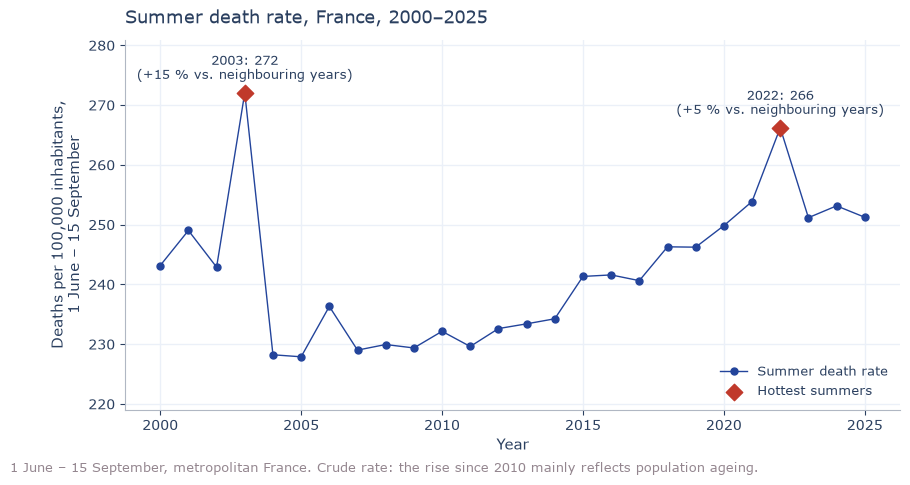

,summer_deaths,population,rate_per_100k
year,,,
2000,143119,58858198,243.2
2001,147588,59266572,249.0
2002,144968,59685899,242.9
2003,163512,60101841,272.1
2004,138090,60505421,228.2
2005,138928,60963264,227.9
2006,145096,61399733,236.3
2007,141515,61795238,229.0
2008,142875,62134866,229.9


In [30]:
import os

# 1. Population on 1 January per département and year (INSEE estimates, Corsica 2A + 2B = 20)
pop = pd.read_csv("data/POPULATION_DEP_2000_2025.csv", sep=";", dtype={"dep": str})
pop_year = pop.groupby("year")["population"].sum()                         # population of mainland France

# 2. Summer deaths (1 June – 15 September) per year
deaths["is_summer"] = deaths["date"].dt.strftime("%m-%d").between("06-01", "09-15")
deaths_year = deaths[deaths["is_summer"]].groupby("year")["deces_total"].sum()

# 3. Summer death rate per 100,000 inhabitants
rate = (deaths_year / pop_year * 1e5).rename("rate_per_100k")
table_rate = pd.DataFrame({"summer_deaths": deaths_year, "population": pop_year, "rate_per_100k": rate.round(1)})

# 4. Plot: no trend line (it explains little, R² = 0.14); highlight the hottest summers instead
hot_years = [2003, 2022]
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(rate.index, rate.values, color=BLUE, marker="o", ms=5, lw=1, label="Summer death rate")
ax.scatter(hot_years, rate[hot_years], color=RED, marker="D", s=70, zorder=3, label="Hottest summers")
for yr in hot_years:
    neighbours = rate[[yr - 1, yr + 1]].mean()                             # average of the year before and after
    ax.annotate(f"{yr}: {rate[yr]:.0f}\n(+{(rate[yr] / neighbours - 1) * 100:.0f} % vs. neighbouring years)",
                (yr, rate[yr]), xytext=(0, 10), textcoords="offset points", ha="center", fontsize=9.5)
ax.set_title("Summer death rate, France, 2000–2025")
ax.set_xlabel("Year")
ax.set_ylabel("Deaths per 100,000 inhabitants,\n1 June – 15 September")
ax.margins(y=0.2)
ax.legend(loc="lower right")
fig.text(0.01, -0.02, "1 June – 15 September, metropolitan France. Crude rate: the rise since 2010 mainly reflects population ageing.",
         fontsize=9, color=GREY)
ax.spines[["top", "right"]].set_visible(False)

os.makedirs("figures", exist_ok=True)
fig.savefig("figures/summer_death_rate_by_year.png", dpi=300, bbox_inches="tight")
fig.savefig("figures/summer_death_rate_by_year.svg", bbox_inches="tight")
plt.show()
table_rate

### Summer death rate by sex

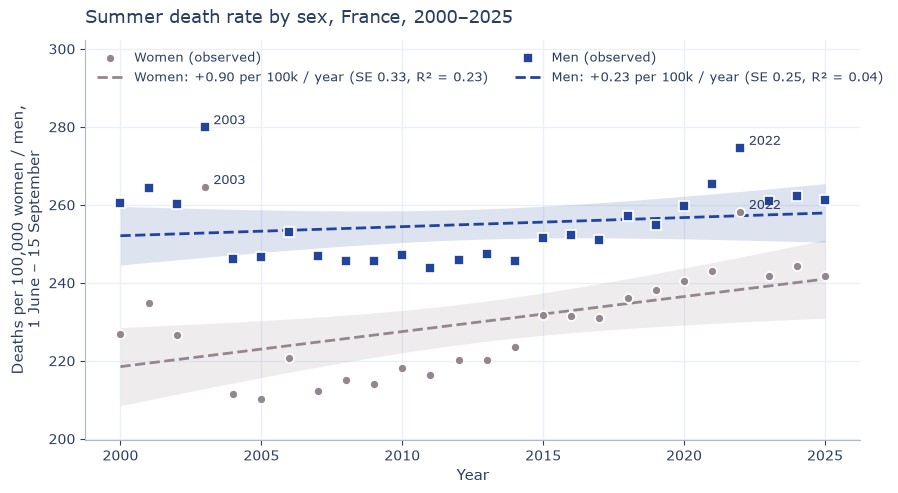

,F,M
year,,
2000,226.8,260.5
2001,234.7,264.2
2002,226.6,260.1
2003,264.6,280.0
2004,211.4,246.2
2005,210.2,246.8
2006,220.7,252.9
2007,212.3,246.8
2008,215.1,245.7


In [31]:
import os

# 1. Population by sex per year (INSEE, 1 January) and summer deaths by sex (1 June – 15 September)
pop = pd.read_csv("data/POPULATION_DEP_2000_2025.csv", sep=";", dtype={"dep": str})
pop_sex = pop.groupby("year")[["population_F", "population_M"]].sum()

summer = deaths[deaths["date"].dt.strftime("%m-%d").between("06-01", "09-15")]
deaths_F = summer[[c for c in age_sex if c.startswith("deces_F_")]].sum(axis=1).groupby(summer["year"]).sum()
deaths_M = summer[[c for c in age_sex if c.startswith("deces_M_")]].sum(axis=1).groupby(summer["year"]).sum()

# 2. Summer death rate per 100,000 women / men
rate_s = pd.DataFrame({"F": deaths_F / pop_sex["population_F"] * 1e5,
                       "M": deaths_M / pop_sex["population_M"] * 1e5})

# 3. Scatter + linear trend with 95 % confidence band, for women and men
fig, ax = plt.subplots(figsize=(10, 5.2))
xs = rate_s.index.values.astype(float)
xg = np.linspace(xs.min(), xs.max(), 100)
for sex, col, name, mk in [("F", GREY, "Women", "o"), ("M", BLUE, "Men", "s")]:
    y = rate_s[sex].values
    b, a = np.polyfit(xs, y, 1)                                      # slope b, intercept a
    resid = y - (a + b * xs)
    n = len(xs)
    s_err = np.sqrt((resid ** 2).sum() / (n - 2))                    # standard error of the regression
    se_b = s_err / np.sqrt(((xs - xs.mean()) ** 2).sum())            # standard error of the slope
    r2 = 1 - (resid ** 2).sum() / ((y - y.mean()) ** 2).sum()
    t = 2.064                                                        # t quantile, 95 %, n - 2 = 24 degrees of freedom
    band = t * s_err * np.sqrt(1 / n + (xg - xs.mean()) ** 2 / ((xs - xs.mean()) ** 2).sum())
    yg = a + b * xg
    ax.fill_between(xg, yg - band, yg + band, color=col, alpha=0.15, lw=0)
    ax.plot(xg, yg, color=col, lw=2, ls="--",
            label=f"{name}: {b:+.2f} per 100k / year (SE {se_b:.2f}, R² = {r2:.2f})")
    ax.scatter(xs, y, color=col, marker=mk, s=42, edgecolor="white", linewidth=1.2, zorder=3, label=f"{name} (observed)")
for yr in [2003, 2022]:
    for sex in ["F", "M"]:
        ax.annotate(str(yr), (yr, rate_s.loc[yr, sex]), xytext=(6, 2), textcoords="offset points", fontsize=9)
ax.set_title("Summer death rate by sex, France, 2000–2025")
ax.set_xlabel("Year")
ax.set_ylabel("Deaths per 100,000 women / men,\n1 June – 15 September")
ax.set_ylim(rate_s.min().min() * 0.95, rate_s.max().max() * 1.08)
h, l = ax.get_legend_handles_labels()
order = [1, 0, 3, 2]                                    # observed then trend, women then men
ax.legend([h[i] for i in order], [l[i] for i in order], loc="upper left", ncol=2)

os.makedirs("figures", exist_ok=True)
fig.savefig("figures/summer_death_rate_by_sex.png", dpi=300, bbox_inches="tight")
fig.savefig("figures/summer_death_rate_by_sex.svg", bbox_inches="tight")
plt.show()

rate_s.round(1)

#### Version 2

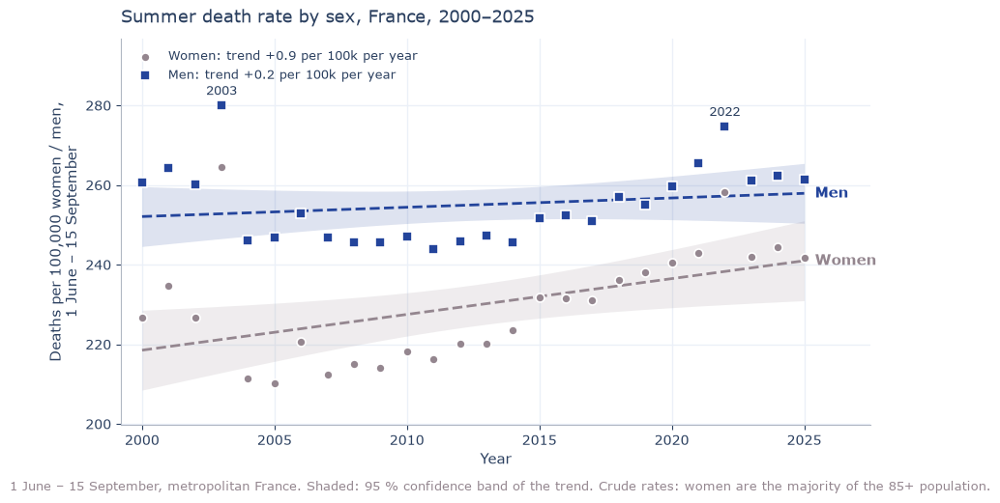

Women: +0.90 per 100k per year (standard error 0.33)
Men: +0.23 per 100k per year (standard error 0.25)


,F,M
year,,
2000,226.8,260.5
2001,234.7,264.2
2002,226.6,260.1
2003,264.6,280.0
2004,211.4,246.2
2005,210.2,246.8
2006,220.7,252.9
2007,212.3,246.8
2008,215.1,245.7


In [32]:
import os

# 1. Population by sex per year (INSEE, 1 January) and summer deaths by sex (1 June – 15 September)
pop = pd.read_csv("data/POPULATION_DEP_2000_2025.csv", sep=";", dtype={"dep": str})
pop_sex = pop.groupby("year")[["population_F", "population_M"]].sum()

summer = deaths[deaths["date"].dt.strftime("%m-%d").between("06-01", "09-15")]
deaths_F = summer[[c for c in age_sex if c.startswith("deces_F_")]].sum(axis=1).groupby(summer["year"]).sum()
deaths_M = summer[[c for c in age_sex if c.startswith("deces_M_")]].sum(axis=1).groupby(summer["year"]).sum()

# 2. Summer death rate per 100,000 women / men
rate_s = pd.DataFrame({"F": deaths_F / pop_sex["population_F"] * 1e5,
                       "M": deaths_M / pop_sex["population_M"] * 1e5})

# 3. Points + linear trend with 95 % confidence band, for women and men
fig, ax = plt.subplots(figsize=(10, 5.2))
xs = rate_s.index.values.astype(float)
xg = np.linspace(xs.min(), xs.max(), 100)
results = {}
for sex, col, name, mk in [("F", GREY, "Women", "o"), ("M", BLUE, "Men", "s")]:
    y = rate_s[sex].values
    b, a = np.polyfit(xs, y, 1)
    resid = y - (a + b * xs)
    n = len(xs)
    s_err = np.sqrt((resid ** 2).sum() / (n - 2))
    se_b = s_err / np.sqrt(((xs - xs.mean()) ** 2).sum())
    t = 2.064                                                        # t quantile, 95 %, 24 degrees of freedom
    band = t * s_err * np.sqrt(1 / n + (xg - xs.mean()) ** 2 / ((xs - xs.mean()) ** 2).sum())
    yg = a + b * xg
    results[name] = (b, se_b)
    ax.fill_between(xg, yg - band, yg + band, color=col, alpha=0.15, lw=0)
    ax.plot(xg, yg, color=col, lw=2, ls="--")
    ax.scatter(xs, y, color=col, marker=mk, s=42, edgecolor="white", linewidth=1.2, zorder=3,
               label=f"{name}: trend {b:+.1f} per 100k per year")
    ax.annotate(name, (xs[-1], yg[-1]), xytext=(8, 0), textcoords="offset points", va="center",
                color=col, fontsize=11, fontweight="bold")
for yr in [2003, 2022]:
    ax.annotate(str(yr), (yr, rate_s.loc[yr, "M"]), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9)
ax.set_title("Summer death rate by sex, France, 2000–2025")
ax.set_xlabel("Year")
ax.set_ylabel("Deaths per 100,000 women / men,\n1 June – 15 September")
ax.set_ylim(rate_s.min().min() * 0.95, rate_s.max().max() * 1.06)
ax.set_xlim(xs.min() - 0.8, xs.max() + 2.5)                          # room for the labels on the right
ax.legend(loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, -0.02, "1 June – 15 September, metropolitan France. Shaded: 95 % confidence band of the trend. "
         "Crude rates: women are the majority of the 85+ population.", fontsize=9, color=GREY)

os.makedirs("figures", exist_ok=True)
fig.savefig("figures/summer_death_rate_by_sex.png", dpi=300, bbox_inches="tight")
fig.savefig("figures/summer_death_rate_by_sex.svg", bbox_inches="tight")
plt.show()

for name, (b, se) in results.items():
    print(f"{name}: {b:+.2f} per 100k per year (standard error {se:.2f})")
rate_s.round(1)

### Deaths by age group and sex, 2000–2025

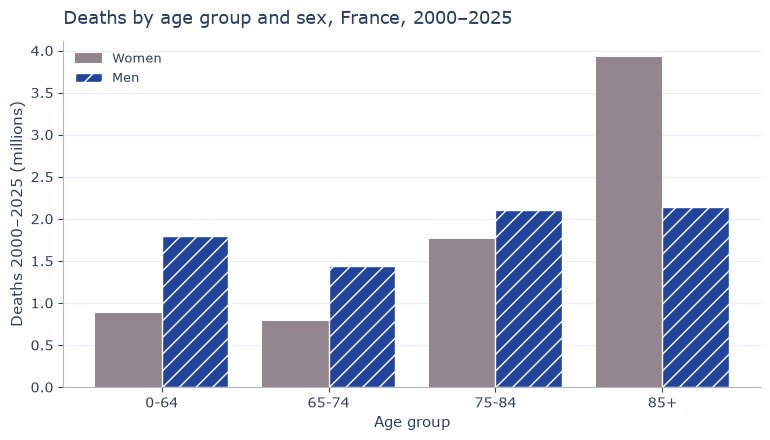

Share of deaths aged 85+: 41 %


,share of all deaths (%)
deces_F_0-64,5.9
deces_F_65-74,5.3
deces_F_75-84,11.9
deces_F_85+,26.4
deces_M_0-64,12.1
deces_M_65-74,9.7
deces_M_75-84,14.2
deces_M_85+,14.4


In [33]:
import os

totals = deaths[age_sex].sum()                               # all deaths 2000–2025 per sex × age group
groups = ["0-64", "65-74", "75-84", "85+"]
x = np.arange(len(groups))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(x - 0.2, [totals[f"deces_F_{g}"] / 1e6 for g in groups], width=0.4, label="Women", color=GREY)
ax.bar(x + 0.2, [totals[f"deces_M_{g}"] / 1e6 for g in groups], width=0.4, label="Men", color=BLUE, hatch="//", edgecolor="white")
ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.set_xlabel("Age group")
ax.set_ylabel("Deaths 2000–2025 (millions)")
ax.set_title("Deaths by age group and sex, France, 2000–2025")
ax.legend()
ax.grid(axis="x", visible=False)
ax.spines[["top", "right"]].set_visible(False)

os.makedirs("figures", exist_ok=True)
fig.savefig("figures/deaths_by_age_sex.png", dpi=300, bbox_inches="tight")
plt.show()

share_85 = (totals["deces_F_85+"] + totals["deces_M_85+"]) / totals.sum() * 100
print(f"Share of deaths aged 85+: {share_85:.0f} %")
(totals / totals.sum() * 100).round(1).rename("share of all deaths (%)").to_frame()

## Step 3: Merge Deaths and Temperature

Up to now we looked at both datasets **separately**. For the bivariate analysis we need them in **one table**:
one row per département and day, with deaths *and* temperature.

### 3.1 Check the keys before merging

We merge on **`date` + `dep`**. This only works if both files use the same codes and the same days.

In [30]:
print("Rows deaths:", len(deaths), "| rows temperature:", len(temp))
print("Départements only in deaths:", set(deaths["dep"]) - set(temp["dep"]))
print("Départements only in temperature:", set(temp["dep"]) - set(deaths["dep"]))
print("Same days:", set(deaths["date"]) == set(temp["date"]))
print("Duplicates (date + dep) in deaths:", deaths.duplicated(["date", "dep"]).sum(),
      "| in temperature:", temp.duplicated(["date", "dep"]).sum())

Rows deaths: 902215 | rows temperature: 902215
Départements only in deaths: set()
Départements only in temperature: set()
Same days: True
Duplicates (date + dep) in deaths: 0 | in temperature: 0


### 3.2 Merge

From the temperature file we only take the columns we need.
`how="inner"` (the default) keeps only rows that exist in both files.

In [31]:
data = deaths.merge(temp[["date", "dep", "tmin", "tmax", "tmean", "canicule_official"]],
                    on=["date", "dep"])

print("Rows after merge:", len(data), "(no rows lost:", len(data) == len(deaths), ")")
data.head()

Rows after merge: 902215 (no rows lost: True )


,date,region,dep,departement,deces_total,deces_F_0-64,deces_F_65-74,deces_F_75-84,deces_F_85+,deces_M_0-64,deces_M_65-74,deces_M_75-84,deces_M_85+,year,is_summer,tmin,tmax,tmean,canicule_official
0,2000-01-01,Auvergne-Rhône-Alpes,01,Ain,14,0,0,2,6,1,2,1,2,2000,False,1.60,5.70,3.65,NaN
1,2000-01-01,Auvergne-Rhône-Alpes,03,Allier,20,3,0,5,4,5,1,1,1,2000,False,5.59,8.58,7.09,NaN
2,2000-01-01,Auvergne-Rhône-Alpes,07,Ardèche,9,1,0,1,3,1,0,2,1,2000,False,1.50,7.00,4.25,NaN
3,2000-01-01,Auvergne-Rhône-Alpes,15,Cantal,15,2,1,2,3,2,1,3,1,2000,False,1.00,5.90,3.45,NaN
4,2000-01-01,Auvergne-Rhône-Alpes,26,Drôme,12,2,2,0,4,1,0,0,3,2000,False,2.10,7.30,4.70,NaN


### 3.3 Add columns for the bivariate analysis

| New column | Meaning |
|---|---|
| `deces_0-64` … `deces_85+` | deaths per age group (women + men) |
| `relative` | deaths compared with the **average day in the same département and year** (1 = normal, 1.2 = 20 % more). This removes the differences in size between départements and the long-term rise due to ageing. |
| `tmean_bin` | daily mean temperature rounded to whole degrees (to group days by temperature) |

In [32]:
for g in ["0-64", "65-74", "75-84", "85+"]:
    data[f"deces_{g}"] = data[f"deces_F_{g}"] + data[f"deces_M_{g}"]

data["relative"] = data["deces_total"] / data.groupby(["dep", "year"])["deces_total"].transform("mean")
data["tmean_bin"] = data["tmean"].round()
data["tmax_bin"] = data["tmax"].round()

data[["date", "departement", "deces_total", "relative", "tmean", "tmean_bin", "canicule_official"]].head()

,date,departement,deces_total,relative,tmean,tmean_bin,canicule_official
0,2000-01-01,Ain,14,1.337510,3.65,4.0,NaN
1,2000-01-01,Allier,20,1.616251,7.09,7.0,NaN
2,2000-01-01,Ardèche,9,1.099466,4.25,4.0,NaN
3,2000-01-01,Cantal,15,2.969173,3.45,3.0,NaN
4,2000-01-01,Drôme,12,1.095808,4.70,5.0,NaN


In [33]:
# Check: relative should be 1 on average in every département-year
print("Mean of relative:", data["relative"].mean().round(3))

# How many heatwave days are there? (département-days)
print("Heatwave département-days:", int(data["canicule_official"].sum()),
      "| share of summer days:", f'{data.loc[data["is_summer"], "canicule_official"].mean():.1%}')

Mean of relative: 1.0
Heatwave département-days: 3475 | share of summer days: 1.3%


## Step 4: Bivariate Analysis
| Graph | Question |
|---|---|
| Deaths by temperature | How does mortality change with temperature? (J-curve) |
| *next:* heatwave days vs. other summer days | How many more deaths on heatwave days? |
| *next:* by age group | Who is affected most? |

### J Curve: Daily max temp and Deaths

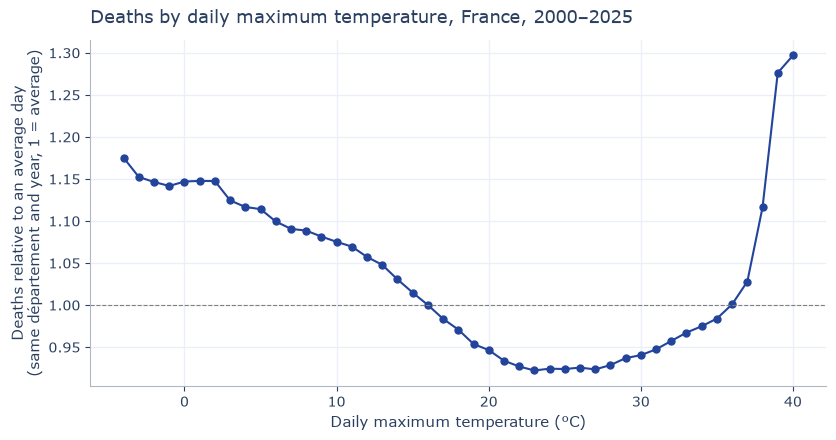

In [35]:
curve = data.groupby("tmax_bin")["relative"].agg(["mean", "size"])
curve = curve[curve["size"] >= 200]                       # leave out temperatures with very few days
HOT = curve["mean"].idxmin()                              # temperature with the lowest mortality

fig, ax = plt.subplots(figsize=(9.5, 4.5))
ax.plot(curve.index, curve["mean"], color=BLUE, marker="o", ms=5, lw=1.5)
ax.axhline(1, color="gray", lw=0.8, ls="--")
ax.set_title("Deaths by daily maximum temperature, France, 2000–2025")
ax.set_xlabel("Daily maximum temperature (°C)")
ax.set_ylabel("Deaths relative to an average day\n(same département and year, 1 = average)")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig("figures/bivariate_deaths_by_temperature.png", dpi=600, bbox_inches="tight")
plt.show()

#print("Lowest mortality at", HOT, "°C | at", curve.index.max(), "°C:",
      #f"{(curve['mean'].iloc[-1] - 1) * 100:+.0f} % vs. an average day")

### Prep Summer days

In [36]:
# summer days only (1 June – 15 September)
summer = data[data["is_summer"]].copy()

# deaths compared with the average SUMMER day in the same département and year (1 = normal summer day)
summer["expected"] = summer.groupby(["dep", "year"])["deces_total"].transform("mean")
summer["relative"] = summer["deces_total"] / summer["expected"]
summer["day_type"] = np.where(summer["canicule_official"] == 1, "Heatwave day", "Other summer day")

summer[["date", "departement", "tmax", "deces_total", "expected", "relative", "day_type"]].head()

,date,departement,tmax,deces_total,expected,relative,day_type
14440,2000-06-01,Ain,25.80,10,9.392523,1.064677,Other summer day
14441,2000-06-01,Allier,28.12,9,11.112150,0.809924,Other summer day
14442,2000-06-01,Ardèche,27.30,13,7.934579,1.638398,Other summer day
14443,2000-06-01,Cantal,26.30,8,4.869159,1.642994,Other summer day
14444,2000-06-01,Drôme,28.10,8,9.897196,0.808310,Other summer day


### Correlation and Regression per Region

In [37]:
# one row per region and summer day: deaths and average max. temperature of the region
summer_reg = (data[data["is_summer"]]
              .groupby(["region", "date"])
              .agg(deaths=("deces_total", "sum"), tmax=("tmax", "mean"))
              .reset_index())
summer_reg["year"] = summer_reg["date"].dt.year

# relative mortality: deaths compared with the average summer day of the same region and year (1 = normal)
summer_reg["relative"] = summer_reg["deaths"] / summer_reg.groupby(["region", "year"])["deaths"].transform("mean")

# for each region: correlation and a simple linear regression  relative = a + b * tmax
rows = []
for region, g in summer_reg.groupby("region"):
    r = g["tmax"].corr(g["relative"])                      # Pearson correlation
    slope, intercept = np.polyfit(g["tmax"], g["relative"], 1)
    rows.append({"Region": region,
                 "Pearson_r": round(r, 2),
                 "R_squared": round(r ** 2, 2),
                 "Extra deaths per +1 °C (%)": round(slope * 100, 1),
                 "Summer days": len(g)})

region_corr = pd.DataFrame(rows).sort_values("Pearson_r", ascending=False).reset_index(drop=True)
region_corr.style.background_gradient(subset=["Pearson_r", "R_squared"], cmap="Reds") \
                 .background_gradient(subset=["Extra deaths per +1 °C (%)"], cmap="Blues") \
                 .format({"Pearson_r": "{:.2f}", "R_squared": "{:.2f}", "Extra deaths per +1 °C (%)": "{:.1f}"})

,Region,Pearson_r,R_squared,Extra deaths per +1 °C (%),Summer days
0,Auvergne-Rhône-Alpes,0.36,0.13,0.8,2782
1,Grand Est,0.34,0.11,0.9,2782
2,Nouvelle-Aquitaine,0.34,0.12,0.8,2782
3,Hauts-de-France,0.32,0.10,0.8,2782
4,Bourgogne-Franche-Comté,0.30,0.09,0.9,2782
5,Bretagne,0.29,0.08,1.1,2782
6,Centre-Val de Loire,0.29,0.08,1.1,2782
7,Pays de la Loire,0.29,0.08,1.0,2782
8,Île-de-France,0.29,0.09,1.1,2782
9,Occitanie,0.28,0.08,0.7,2782


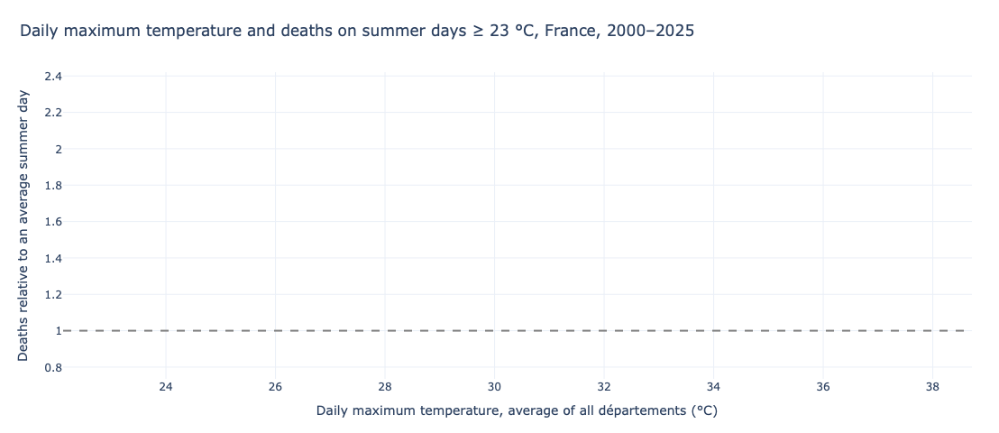

2069 hot summer days | +1.2 % deaths per +1 °C | r = 0.44 | R² = 0.20


In [38]:
# France as a whole, one point per summer day: total deaths and average max. temperature of the 95 départements
fr = summer.groupby("date").agg(deaths=("deces_total", "sum"), tmax=("tmax", "mean")).reset_index()
fr["year"] = fr["date"].dt.year
fr["relative"] = fr["deaths"] / fr.groupby("year")["deaths"].transform("mean")   # 1 = average summer day of that year
fr_hot = fr[fr["tmax"] >= HOT]                                                     # only days above the J-curve minimum

fig = px.scatter(fr_hot, x="tmax", y="relative",
                 color_discrete_sequence=[BLUE],
                 hover_data=["date", "deaths"],
                 trendline="ols", opacity=0.4,
                 labels={"tmax": "Daily maximum temperature, average of all départements (°C)",
                         "relative": "Deaths relative to an average summer day"},
                 title=f"Daily maximum temperature and deaths on summer days ≥ {HOT:.0f} °C, France, 2000–2025")
fig.update_traces(marker=dict(size=5), selector=dict(mode="markers"))
fig.update_traces(line=dict(width=3, color=RED), selector=dict(mode="lines"))
fig.add_hline(y=1, line_dash="dash", line_color="gray")
fig.update_layout(height=480, margin=dict(l=70, r=30, t=80, b=60))
fig.write_html("figures/bivariate_scatter_france.html")
fig.show()

slope, intercept = np.polyfit(fr_hot["tmax"], fr_hot["relative"], 1)
r = fr_hot["tmax"].corr(fr_hot["relative"])
print(f"{len(fr_hot)} hot summer days | +{slope * 100:.1f} % deaths per +1 °C | r = {r:.2f} | R² = {r ** 2:.2f}")

In [42]:
DEPS = {"75": "Paris", "13": "Bouches-du-Rhône (Marseille)"}

two = summer[summer["dep"].isin(DEPS) & (summer["tmax"] >= HOT)].copy()
two["name"] = two["dep"].map(DEPS)

fig = px.scatter(two, x="tmax", y="relative",
                 facet_col="name", color="name",
                 category_orders={"name": list(DEPS.values())},
                 color_discrete_sequence=[BLUE, GREY],
                 hover_data=["date", "deces_total"],
                 trendline="ols", opacity=0.3,
                 labels={"tmax": "Daily maximum temperature (°C)",
                         "relative": "Deaths relative to an average summer day",
                         "name": ""},
                 title=f"Daily maximum temperature and deaths on summer days ≥ {HOT:.0f} °C, Paris vs. Bouches-du-Rhône, 2000–2025")
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.update_traces(marker=dict(size=5), selector=dict(mode="markers"))
fig.update_traces(line=dict(width=3, color=RED), selector=dict(mode="lines"))
fig.add_hline(y=1, line_dash="dash", line_color="gray")
fig.update_xaxes(matches=None, showticklabels=True)         # Marseille gets much hotter: own x-axis
fig.update_yaxes(showticklabels=True)
fig.update_layout(showlegend=False, height=480,
                  margin=dict(l=70, r=30, t=80, b=60))
fig.write_html("figures/bivariate_paris_vs_marseille.html")
fig.show()

# the regression slopes, with and without 2003
#for dep, name in DEPS.items():
    #g = two[two["dep"] == dep]
    #s_all = np.polyfit(g["tmax"], g["relative"], 1)[0] * 100
    #g2 = g[g["year"] != 2003]
    #s_no03 = np.polyfit(g2["tmax"], g2["relative"], 1)[0] * 100
    #print(f"{name}: {s_all:+.1f} % per °C  |  without 2003: {s_no03:+.1f} % per °C")

### Maps: Summer Heat vs. Summer Mortality

Left: summer max. temperature compared with the region's (or département's) own 2000–2025 average (°C).
Right: summer death rate compared with its own 2000–2025 average (%).
Use the slider to move through the years. One map for regions, one for départements.

*Note:* the death rate is the crude rate, so it rises slowly over time because of population ageing.

In [39]:
# Double map: summer heat (left) and summer mortality (right), anomalies vs each unit's own 2000–2025 average
# This cell only prepares the data and the drawing function; the maps follow in the next two cells.
from pathlib import Path
import json, urllib.request
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from plotly.colors import sample_colorscale

FIG = Path("figures"); FIG.mkdir(exist_ok=True)

# ---------- 1. Data: one row per region x year and per departement x year ----------
# daily deaths + daily max. temperature per département, and the population of each département and year
pop = pd.read_csv("data/POPULATION_DEP_2000_2025.csv", sep=";", dtype={"dep": str})
p = deaths[["date", "dep", "region", "deces_total"]].merge(temp[["date", "dep", "tmax"]], on=["date", "dep"])
p["year"] = p["date"].dt.year
p = p.merge(pop[["year", "dep", "population"]], on=["year", "dep"])
p = p.rename(columns={"deces_total": "deaths_total", "population": "pop_total"})

s = p[p["date"].dt.strftime("%m-%d").between("06-01", "09-15")].copy()      # summer = 1 June - 15 September

def summer_table(unit):
    g = s.groupby([unit, "year"])
    t = pd.DataFrame({"tmax": g.tmax.mean(), "deaths": g.deaths_total.sum()})
    t["pop"] = s.groupby([unit, "year", "dep"]).pop_total.first().groupby([unit, "year"]).sum()
    t["rate"] = t.deaths / t["pop"] * 1e5                                             # summer deaths per 100,000
    t = t.reset_index()
    t["tmax_anom"] = t.tmax - t.groupby(unit).tmax.transform("mean")                  # °C vs own 2000-2025 mean
    t["rate_anom"] = (t.rate / t.groupby(unit).rate.transform("mean") - 1) * 100      # % vs own 2000-2025 mean
    return t

reg = summer_table("region"); dep = summer_table("dep")
reg.round(3).to_csv(FIG / "double_map_region_year.csv", index=False)
dep.round(3).to_csv(FIG / "double_map_departement_year.csv", index=False)
for name, t in [("regions", reg), ("départements", dep)]:
    r = t[["tmax_anom", "rate_anom"]].corr().iloc[0, 1]
    print(f"{name}: correlation Tmax anomaly vs death-rate anomaly = {r:.2f}  (n = {len(t)})")
# ---------- 2. Drawing helpers ----------
COS_LAT = np.cos(np.radians(46.5))     # so France is not stretched horizontally

def outline(geom):
    polys = [geom["coordinates"]] if geom["type"] == "Polygon" else geom["coordinates"]
    xs, ys = [], []
    for poly in polys:
        ring = poly[0]
        xs += [lon * COS_LAT for lon, lat in ring] + [None]
        ys += [lat for lon, lat in ring] + [None]
    return xs, ys

def load_geo(fname, url):
    f = Path(fname)
    if not f.exists():
        urllib.request.urlretrieve(url, f)
    return json.loads(f.read_text(encoding="utf-8"))

# colour scales start at 0: white = normal or below normal, darker = further above normal
HEAT_SCALE = [[0.0, "#ffffff"], [0.35, "#fcae91"], [0.7, "#de2d26"], [1.0, "#67000d"]]   # white -> dark red
MORT_SCALE = [[0.0, "#ffffff"], [0.35, "#9ecae1"], [0.7, "#3182bd"], [1.0, "#08306b"]]   # white -> dark blue

def colour_fn(scale, lim):
    def f(v):                                       # every value <= 0 is drawn white
        x = 0.0 if pd.isna(v) else min(max(v / lim, 0), 1)
        return sample_colorscale(scale, [x])[0]
    return f

def double_map(t, unit, shapes, unit_of_shape, title, fname, start=2003):
    years = sorted(t.year.unique())
    val = t.set_index([unit, "year"])
    # upper limits = 98th percentile of positive anomalies, so 2003 does not wash out the other years
    t_lim = float(np.ceil(np.percentile(t.tmax_anom[t.tmax_anom > 0], 98) * 2) / 2)
    r_lim = float(np.ceil(np.percentile(t.rate_anom[t.rate_anom > 0], 98) / 5) * 5)
    red, blue = colour_fn(HEAT_SCALE, t_lim), colour_fn(MORT_SCALE, r_lim)
    names = sorted(shapes)

    def traces(year, with_geometry):
        out = []
        for var, fn in [("tmax_anom", red), ("rate_anom", blue)]:
            for n in names:
                row = val.loc[(unit_of_shape[n], year)]
                txt = (f"<b>{n}</b> — {year}<br>Summer mean Tmax: {row.tmax:.1f} °C ({row.tmax_anom:+.1f} °C vs normal)"
                       f"<br>Summer deaths: {int(row.deaths):,} — {row.rate:.0f} per 100,000 ({row.rate_anom:+.1f} % vs normal)")
                kw = dict(fillcolor=fn(row[var]), text=txt)
                if with_geometry:
                    xs, ys = shapes[n]
                    kw.update(x=xs, y=ys, fill="toself", mode="lines", line=dict(color="#a9a39b", width=0.7),
                              hoveron="fills", hoverinfo="text", showlegend=False)
                out.append(go.Scatter(**kw))
        return out

    fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.08,
                        subplot_titles=("Heat: summer max. temperature (°C)", "Mortality: summer death rate (%)"))
    k = len(names)
    for i, tr in enumerate(traces(start, True)):
        fig.add_trace(tr, row=1, col=1 if i < k else 2)
    fig.add_trace(go.Scatter(x=[None], y=[None], mode="markers", hoverinfo="skip", showlegend=False,
                             marker=dict(colorscale=HEAT_SCALE, cmin=0, cmax=t_lim, color=[0], showscale=True,
                                         colorbar=dict(title="°C", x=0.445, len=0.7, ticksuffix=" °C", thickness=16))), row=1, col=1)
    fig.add_trace(go.Scatter(x=[None], y=[None], mode="markers", hoverinfo="skip", showlegend=False,
                             marker=dict(colorscale=MORT_SCALE, cmin=0, cmax=r_lim, color=[0], showscale=True,
                                         colorbar=dict(title="%", x=1.0, len=0.7, ticksuffix=" %", thickness=16))), row=1, col=2)
    fig.frames = [go.Frame(name=str(y), data=traces(y, False), traces=list(range(2 * k))) for y in years]
    fig.update_xaxes(domain=[0.0, 0.38], row=1, col=1)
    fig.update_xaxes(domain=[0.53, 0.91], row=1, col=2)
    fig.layout.annotations[0].x = 0.19; fig.layout.annotations[1].x = 0.72
    fig.update_annotations(font_size=14)                  # subplot titles a bit smaller than the main title
    for c in (1, 2):
        fig.update_xaxes(visible=False, row=1, col=c)
        fig.update_yaxes(visible=False, scaleanchor=f"x{'' if c == 1 else c}", row=1, col=c)
    fig.update_layout(
        title=dict(text=title), height=680, margin=dict(l=10, r=10, t=90, b=10),
        paper_bgcolor="white", plot_bgcolor="white",
        sliders=[dict(active=years.index(start), currentvalue=dict(prefix="Year: ", font=dict(size=16)),
                      pad=dict(t=10), len=0.84, x=0.16,
                      steps=[dict(label=str(y), method="animate",
                                  args=[[str(y)], dict(mode="immediate", frame=dict(duration=0, redraw=True),
                                                       transition=dict(duration=0))]) for y in years])],
        updatemenus=[dict(type="buttons", direction="left", x=0.0, y=0.02, xanchor="left", yanchor="top",
                          pad=dict(t=12), showactive=False,
                          buttons=[dict(label="▶️ Play", method="animate",
                                        args=[None, dict(frame=dict(duration=900, redraw=True), fromcurrent=True,
                                                         transition=dict(duration=0))]),
                                   dict(label="■ Pause", method="animate",
                                        args=[[None], dict(mode="immediate", frame=dict(duration=0, redraw=False))])])])
    fig.write_html(FIG / fname, include_plotlyjs=True, auto_play=False)
    return fig

regions: correlation Tmax anomaly vs death-rate anomaly = 0.57  (n = 338)
départements: correlation Tmax anomaly vs death-rate anomaly = 0.48  (n = 2470)


#### Map by region

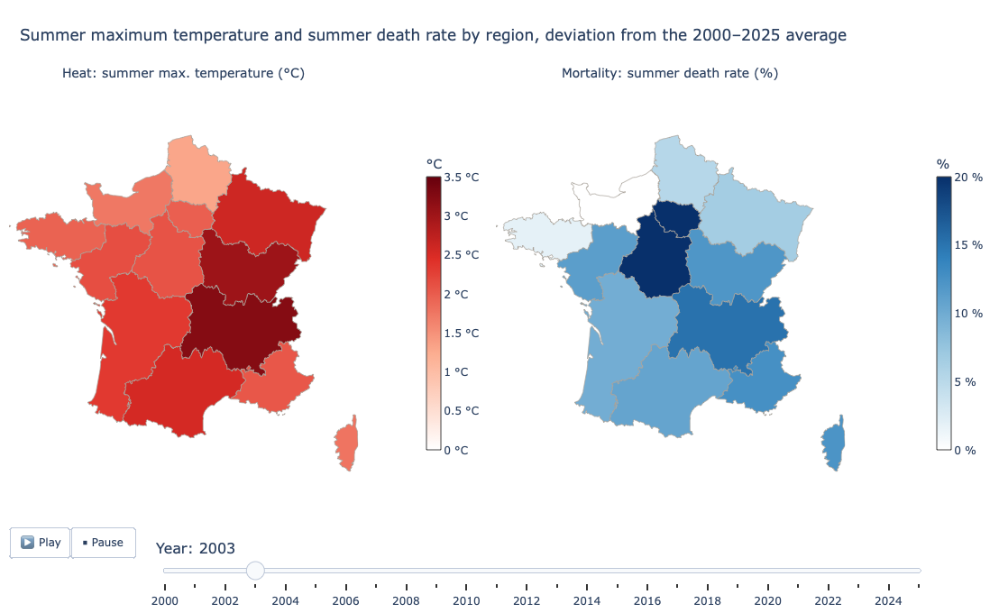

In [40]:
# ---------- Map 1: regions ----------
geo_r = load_geo("regions_france.geojson",
                 "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/regions-version-simplifiee.geojson")
shapes_r = {f["properties"]["nom"]: outline(f["geometry"]) for f in geo_r["features"]}
figA = double_map(reg, "region", shapes_r, {n: n for n in shapes_r},
                  "Summer maximum temperature and summer death rate by region, deviation from the 2000–2025 average",
                  "double_map_regions.html")
figA.show()

#### Map by département

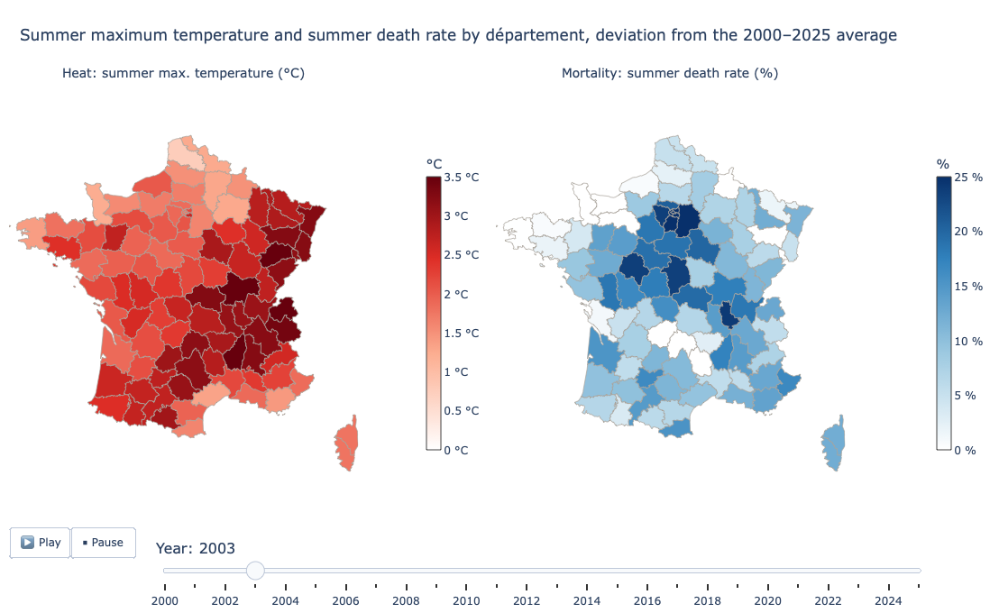

In [41]:
# ---------- Map 2: départements ----------
geo_d = load_geo("departements_france.geojson",
                 "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements-version-simplifiee.geojson")
shapes_d = {f"{f['properties']['code']} {f['properties']['nom']}": outline(f["geometry"]) for f in geo_d["features"]}
unit_d = {n: ("20" if n[:2] in ("2A", "2B") else n[:2]) for n in shapes_d}      # Corsica is merged in the data
figB = double_map(dep, "dep", shapes_d, unit_d,
                  "Summer maximum temperature and summer death rate by département, deviation from the 2000–2025 average",
                  "double_map_departements.html")
figB.show()